# LFER analysis V2: LFER parametrization for combined dataset

This notebook fits a single reactivity scale to the combined dataset from the high-throughput kinetics of this work (`hte_kinetics`) and literature rate constants. Every valid reaction is subjected to the same automated coverage and residual-based selection; the source label is retained only for traceability and diagnostics. Reactions measured in both datasets contribute all of their measurements and no source is given precedence. The selected system is globally refitted, then provides the fixed reference scale used to place discarded species.

$$\lg k_2=N_\mathrm{P}+s_\mathrm{N,P}E_\mathrm{P}$$

The scale is anchored by $s_\mathrm{N,P}(Nu5)=1$ and $E_\mathrm{P}(\mathrm{P7})=0$. Pyridines retain the coverage-dependent mean-$s$ placement rule. Electrophiles defined by one selected nucleophile are report-only definitions with propagated bootstrap intervals and are never used downstream.

Workflow:

1. Load and normalize the `hte_kinetics` and literature data.
2. Merge both datasets into one combined table; the source label is kept for traceability only.
3. Select the joint reference system by coverage and residual diagnostics, with both sources competing on identical criteria.
4. Fit and bootstrap the selected joint scale.
5. Place the discarded species on that fixed scale: electrophiles from selected nucleophiles (single-nucleophile estimates report-only), then nucleophiles on the selected plus reliably attached electrophiles.
6. Assemble the fully expanded scale with propagated bootstrap uncertainty.
7. Export the results and supporting metadata.

## 0. Configuration and plot style

In [1]:
import math
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.transforms import blended_transform_factory
from matplotlib.ticker import MaxNLocator
from scipy.optimize import least_squares

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 60)

# --- uniform plot style: Arial, one font size everywhere, tick marks inside ---
FONTSIZE = 12
mpl.rcParams.update({
    "font.family": "Arial", "font.size": FONTSIZE,
    "axes.titlesize": FONTSIZE, "axes.labelsize": FONTSIZE,
    "xtick.labelsize": FONTSIZE, "ytick.labelsize": FONTSIZE, "legend.fontsize": FONTSIZE,
    "xtick.direction": "in", "ytick.direction": "in",
    "xtick.major.size": 4, "ytick.major.size": 4, "axes.linewidth": 0.9,
    "figure.dpi": 110, "savefig.dpi": 150,
})

class CONFIG:
    # --- input / output files ---
    OWN_FILE  = "stage6_k2_high_selection_summary.xlsx"
    OWN_SHEET = "summary"
    LIT_FILE  = "phosphorylation_additional_2026_07_31.xlsx"
    OUTPUT_FILE = "lfer_analysis_v2_results.xlsx"
    METADATA_FILE = "lfer_analysis_v2_metadata.xlsx"
    DATASET_LABEL = "hte_kinetics"

    # --- electrophile identifiers ---
    P_IDS = ("P5", "P6", "P7", "P8", "P9")
    E_ID_MAP = {pid: pid for pid in P_IDS}

    # --- single model form & anchoring ---
    ANCHOR_NUC = "3,4-lutidine"   # reference nucleophile: s_N,P = 1; N_P is fitted
    ANCHOR_ELEC = "P7"            # reference electrophile: E_P = 0

    # --- labels ---
    WATER_LABEL = "water"

    # --- no quality pre-filter: every raw HTE and literature measurement enters
    #     the same automated selection; coverage and residual rules do all filtering ---

    # --- automated core selection ---
    MIN_ELECTROPHILES = 3         # a nucleophile enters a refit only with >=3 electrophiles
    MIN_NUC_PER_ELEC = 2          # a jointly fitted electrophile needs >=2 distinct nucleophiles
    OUTLIER_MAD_K = 2.5           # flag reaction as outlier if |resid| > k * sigma_MAD

    # --- least-squares bounds (identifiability guard) ---
    S_BOUNDS = (0.0, 1.5); N_BOUNDS = (-60.0, 60.0); E_BOUNDS = (-60.0, 60.0)

    # --- bootstrap ---
    N_BOOT = 600; BOOT_SEED = 42

    # --- discarded-electrophile attachment: E is reliable from >=2 selected nucleophiles ---
    MIN_NUC_FOR_NEW_E = 2

    # --- low-coverage nucleophile extension ---
    PYRIDINE_NAME_PATTERNS = ("pyridine", "lutidine", "picoline", "collidine",
                              "nicotinamide", "nicotinicacid", "nicotinic acid")
    # a freely fitted s running into an imposed bound is not identifiable -> reject the species
    REJECT_S_AT_BOUNDS = True

    # --- default nucleophiles for the "lg k vs E" plots (present in the core) ---
    LGK_VS_E_NUCLEOPHILES = ["piperidine", "3,4-lutidine", "methylamine", "water"]

def is_pyridine(name, cfg=CONFIG):
    "True for ring-N pyridine nucleophiles (incl. lutidines, picolines, nicotin(o)amides)."
    n = str(name).lower()
    return any(pat in n for pat in cfg.PYRIDINE_NAME_PATTERNS)


def norm_name(x):
    "Normalize a species name for matching across datasets."
    return str(x).strip().lower().replace("_", " ")


## 1. Load and clean the data

The high-throughput table holds the final mechanism-specific rate constants of this work; the
literature table supplies independently reported second-order rate constants. Both are converted to
$\lg k$, nucleophiles are matched by name with an audit table for mismatches, and every row
keeps a source label for traceability only — provenance does not influence any selection or fitting
decision.

In [2]:
def load_own(cfg=CONFIG):
    s = pd.read_excel(cfg.OWN_FILE, sheet_name=cfg.OWN_SHEET)
    s = s[s["final_k2_high"].notna() & (s["final_k2_high"] > 0)].copy()
    s["electrophile"] = s["PX"].astype(str).str.strip()
    s["electrophile_id"] = s["electrophile"]
    s["nucleophile"]  = s["nu_name"].map(norm_name)
    is_water = s["nucleophile"].str.contains("water")
    s["nucleophile"] = np.where(is_water, cfg.WATER_LABEL, s["nucleophile"])
    k2 = s["final_k2_high"].astype(float)
    s["lgk"] = np.log10(k2)
    out = pd.DataFrame({
        "nucleophile": s["nucleophile"], "nucleophile_id": s["nu_id"],
        "electrophile": s["electrophile"], "electrophile_id": s["electrophile_id"], "lgk": s["lgk"],
        "k2": k2, "rel_error": s["final_k2_high_rel_error"], "method": s["final_k2_high_method"],
        "source": cfg.DATASET_LABEL,
    }).dropna(subset=["nucleophile", "electrophile", "lgk"]).reset_index(drop=True)
    return out

own_raw = load_own()
NUCLEOPHILE_ID_MAP = (own_raw[["nucleophile", "nucleophile_id"]]
                      .dropna().drop_duplicates("nucleophile")
                      .set_index("nucleophile")["nucleophile_id"].to_dict())
ELECTROPHILE_ID_MAP = CONFIG.E_ID_MAP.copy()
# Both maps are extended with the literature compound numbers once that table is loaded
# (next section), so every figure labels every species by its compound number.

def bold_id(label):
    label = str(label)
    # MathText bold keeps Nu/P identifiers visually distinct in all plots.
    return rf"$\mathbf{{{label}}}$" if label.startswith(("Nu", "P")) else label

def nucleophile_id(n, bold=True):
    lab = NUCLEOPHILE_ID_MAP.get(n, n)
    return bold_id(lab) if bold else lab

def nucleophile_name_id(n, bold=True):
    nid = NUCLEOPHILE_ID_MAP.get(n)
    if not nid:
        return n
    return f"{n} ({bold_id(nid) if bold else nid})"

def electrophile_id(e, bold=True):
    lab = ELECTROPHILE_ID_MAP.get(e, e)
    return bold_id(lab) if bold else lab

def species_id(species, role, bold=True):
    return nucleophile_id(species, bold=bold) if role == "nucleophile" else electrophile_id(species, bold=bold)


# Guard: a nucleophile ID shared by two species would make every ID-labelled plot ambiguous.
_dup_ids = (own_raw[["nucleophile", "nucleophile_id"]].dropna().drop_duplicates()
            .groupby("nucleophile_id")["nucleophile"].agg(list))
_dup_ids = {k: v for k, v in _dup_ids.items() if len(v) > 1}
if _dup_ids:
    print("WARNING: nucleophile IDs used for more than one species in", CONFIG.OWN_FILE, "->", _dup_ids)

print(f"Valid measurements: {len(own_raw)}")
print(f"Nucleophiles: {own_raw.nucleophile.nunique()}   Electrophiles: {sorted(own_raw.electrophile.unique())}")
own_raw.head()


Valid measurements: 102
Nucleophiles: 29   Electrophiles: ['P5', 'P6', 'P7', 'P8', 'P9']


,nucleophile,nucleophile_id,electrophile,electrophile_id,lgk,k2,rel_error,method,source
0,water,Nu1,P5,P5,-4.622437,0.000024,0.022792,k0_water_hydroxide_fit,hte_kinetics
1,pyridine,Nu2,P5,P5,-3.948163,0.000113,0.313814,B_global,hte_kinetics
2,3-methylpyridine,Nu3,P5,P5,-3.975664,0.000106,0.400018,B_global,hte_kinetics
3,4-methylpyridine,Nu4,P5,P5,-3.874075,0.000134,0.189301,A_fit,hte_kinetics
4,"3,4-lutidine",Nu5,P5,P5,-3.926494,0.000118,0.197956,A_fit,hte_kinetics


In [3]:
# Literature loader and name-standardization audit
def literature_name_standardization(cfg=CONFIG):
    own_names = pd.read_excel(cfg.OWN_FILE, sheet_name=cfg.OWN_SHEET)["nu_name"].dropna().astype(str).str.strip()
    canonical = {norm_name(x): x for x in own_names.unique()}
    canonical[norm_name(cfg.WATER_LABEL)] = cfg.WATER_LABEL
    raw = pd.read_excel(cfg.LIT_FILE)["Nucleophile Name"].dropna().astype(str).str.strip().drop_duplicates()
    rows = []
    for raw_name in sorted(raw):
        normalized = norm_name(raw_name)
        target = canonical.get(normalized)
        rows.append(dict(
            literature_name=raw_name,
            notebook_normalized_name=normalized,
            suggested_name_in_literature_file=target,
            currently_mapped_to_hte_species=bool(target),
            needs_file_change=bool(target) and raw_name != target,
            reason=("synonym fallback" if norm_name(raw_name) != normalized else "case/format standardization") if bool(target) and raw_name != target else "",
        ))
    return pd.DataFrame(rows)

lit_name_standardization = literature_name_standardization()
lit_name_change_recommendations = lit_name_standardization.query("needs_file_change").reset_index(drop=True)
print(f"Literature nucleophile names that should be changed to match {CONFIG.OWN_FILE}:")
display(lit_name_change_recommendations)

def load_literature(cfg=CONFIG):
    a = pd.read_excel(cfg.LIT_FILE)
    a = a.rename(columns={"Electrophile": "electrophile", "Nucleophile Name": "nucleophile",
                          "log k2": "lgk", "Source": "lit_source"})
    a["raw_nucleophile_name"] = a["nucleophile"].astype(str).str.strip()
    a["raw_electrophile_name"] = a["electrophile"].astype(str).str.strip()
    a["nucleophile"] = a["nucleophile"].map(norm_name)
    a["electrophile"] = a["electrophile"].astype(str).str.strip()
    # Compound numbers come from the literature table itself. "Nu"/"P" prefixes are
    # case-normalized so that e.g. NU56 and Nu56 are recognized as the same compound.
    def _cid(series, prefix):
        v = series.astype(str).str.strip()
        return v.str.replace(rf"^{prefix}", prefix, case=False, regex=True)
    a["nucleophile_id"] = _cid(a["Nu_ID"], "Nu")
    a["electrophile_id"] = _cid(a["P_ID"], "P")
    a["lgk"] = pd.to_numeric(a["lgk"], errors="coerce")
    a["source"] = "literature"; a["rel_error"] = np.nan; a["method"] = "literature"
    a["k2"] = 10.0**a["lgk"]
    return a.dropna(subset=["nucleophile", "electrophile", "lgk"]).reset_index(drop=True)

lit = load_literature()

def _register_ids(frame, name_col, id_col, target, label):
    pairs = frame[[name_col, id_col]].dropna().drop_duplicates()
    clashes = []
    for name, cid in pairs.itertuples(index=False):
        if name in target and target[name] != cid:
            clashes.append(f"{name}: {target[name]} vs {cid}")
        target[name] = cid
    reused = (pairs.groupby(id_col)[name_col].nunique() > 1)
    if reused.any():
        clashes += [f"{i} used for several species" for i in reused[reused].index]
    if clashes:
        print(f"WARNING: inconsistent {label} compound numbers ->", "; ".join(clashes))

_register_ids(lit, "nucleophile", "nucleophile_id", NUCLEOPHILE_ID_MAP, "nucleophile")
_register_ids(lit, "electrophile", "electrophile_id", ELECTROPHILE_ID_MAP, "electrophile")
print(f"Compound numbers registered: {len(NUCLEOPHILE_ID_MAP)} nucleophiles, "
      f"{len(ELECTROPHILE_ID_MAP)} electrophiles")

print(f"Literature reactions: {len(lit)} | electrophiles: {lit.electrophile.nunique()} | nucleophiles: {lit.nucleophile.nunique()}")


Literature nucleophile names that should be changed to match stage6_k2_high_selection_summary.xlsx:


,literature_name,notebook_normalized_name,suggested_name_in_literature_file,currently_mapped_to_hte_species,needs_file_change,reason


Compound numbers registered: 59 nucleophiles, 34 electrophiles
Literature reactions: 176 | electrophiles: 33 | nucleophiles: 49


## 2. LFER fitting engine

All $N_\mathrm{P}$, $s_\mathrm{N,P}$, and $E_\mathrm{P}$ values are fitted simultaneously by
bounded nonlinear least squares in logarithmic rate space. The reference nucleophile Nu5 is
held at $s_\mathrm{N,P}=1$ with fitted $N_\mathrm{P}$; the reference electrophile P7 is held at
$E_\mathrm{P}=0$. Bounds keep $0 \leq s_\mathrm{N,P} \leq 1.5$ while allowing broad
$N_\mathrm{P}$ and $E_\mathrm{P}$ ranges. Per-observation **weights** support the Bayesian
bootstrap (Section 5).

In [4]:
def fit_lfer(data, cfg=CONFIG, anchor_nuc=None, anchor_elec=None, weights=None):
    anchor_nuc = anchor_nuc or cfg.ANCHOR_NUC
    anchor_elec = anchor_elec or cfg.ANCHOR_ELEC
    d = data.reset_index(drop=True)
    nucs, elecs = sorted(d["nucleophile"].unique()), sorted(d["electrophile"].unique())
    if anchor_nuc not in nucs:
        raise ValueError(f"anchor nucleophile {anchor_nuc!r} not in data")
    if anchor_elec not in elecs:
        raise ValueError(f"anchor electrophile {anchor_elec!r} not in data")

    y, ni, ei = d["lgk"].to_numpy(), d["nucleophile"].to_numpy(), d["electrophile"].to_numpy()
    sw = np.sqrt(np.ones(len(d)) if weights is None else np.asarray(weights, float))
    E0 = {e: d.loc[d.electrophile == e, "lgk"].mean() for e in elecs}
    E0_anchor = E0[anchor_elec]

    free_s_n = [n for n in nucs if n != anchor_nuc]
    free_e = [e for e in elecs if e != anchor_elec]
    sdx = {n: k for k, n in enumerate(free_s_n)}
    ndx = {n: k for k, n in enumerate(nucs)}
    edx = {e: k for k, e in enumerate(free_e)}
    ns, nn, ne = len(free_s_n), len(nucs), len(free_e)

    N0 = []
    for n in nucs:
        at_anchor_e = d[(d["nucleophile"] == n) & (d["electrophile"] == anchor_elec)]["lgk"]
        N0.append(float(at_anchor_e.mean() if len(at_anchor_e) else d.loc[d.nucleophile == n, "lgk"].mean()))
    x0 = np.r_[np.ones(ns), N0, [E0[e] - E0_anchor for e in free_e]]
    lo = np.r_[np.full(ns, cfg.S_BOUNDS[0]), np.full(nn, cfg.N_BOUNDS[0]), np.full(ne, cfg.E_BOUNDS[0])]
    hi = np.r_[np.full(ns, cfg.S_BOUNDS[1]), np.full(nn, cfg.N_BOUNDS[1]), np.full(ne, cfg.E_BOUNDS[1])]
    x0 = np.clip(x0, lo + 1e-9, hi - 1e-9)

    is_anchor_n = (ni == anchor_nuc)
    is_anchor_e = (ei == anchor_elec)
    s_pos = np.array([sdx.get(n, 0) for n in ni])
    n_pos = np.array([ndx[n] for n in ni])
    e_pos = np.array([edx.get(e, 0) for e in ei])

    def resid(x):
        s, N, E = x[:ns], x[ns:ns+nn], x[ns+nn:]
        sv = np.where(is_anchor_n, 1.0, s[s_pos])
        Ev = np.where(is_anchor_e, 0.0, E[e_pos])
        Nv = N[n_pos]
        return sw * (sv * Ev + Nv - y)

    res = least_squares(resid, x0, bounds=(lo, hi), method="trf", max_nfev=30000)
    s, N, E = res.x[:ns], res.x[ns:ns+nn], res.x[ns+nn:]
    rows = []
    for k, n in enumerate(nucs):
        rows.append(dict(type="nucleophile", species=n, parameter="N", estimate=N[k]))
        rows.append(dict(type="nucleophile", species=n, parameter="s",
                         estimate=1.0 if n == anchor_nuc else s[sdx[n]]))
    rows.append(dict(type="electrophile", species=anchor_elec, parameter="E", estimate=0.0))
    for k, e in enumerate(free_e):
        rows.append(dict(type="electrophile", species=e, parameter="E", estimate=E[k]))

    params = pd.DataFrame(rows)
    fitted = _apply_params(d, params)
    r = fitted["residual"].to_numpy(); yv = fitted["lgk"].to_numpy()
    ss_res, ss_tot = float(np.sum(r**2)), float(np.sum((yv - yv.mean())**2))
    metrics = dict(n=len(d), n_nuc=len(nucs), n_elec=len(elecs),
                   rmse=float(np.sqrt(np.mean(r**2))), mae=float(np.mean(np.abs(r))),
                   r2=(1 - ss_res/ss_tot) if ss_tot > 0 else np.nan, success=bool(res.success))
    return params, fitted, metrics, res


def _param_lookup(params):
    return params.set_index(["type", "species", "parameter"])["estimate"].to_dict()

def predict_lgk(params, nucleophile, electrophile):
    p = _param_lookup(params) if isinstance(params, pd.DataFrame) else params
    N = p[("nucleophile", nucleophile, "N")]
    E = p[("electrophile", electrophile, "E")]
    return N + p[("nucleophile", nucleophile, "s")] * E

def _apply_params(data, params):
    p = _param_lookup(params)
    out = data.copy()
    out["lgk_calc"] = [predict_lgk(p, n, e) for n, e in zip(data["nucleophile"], data["electrophile"])]
    out["residual"] = out["lgk"] - out["lgk_calc"]
    return out

def param_table(params):
    nuc = params.query("type=='nucleophile'").pivot(index="species", columns="parameter", values="estimate")
    ele = params.query("type=='electrophile'").pivot(index="species", columns="parameter", values="estimate")
    return nuc, ele


In [5]:
# --- shared plotting helpers (SI-oriented style) ---
def _despine(ax, sides=("top", "right")):
    "House style for all SI plots: no top/right frame lines."
    for side in sides:
        ax.spines[side].set_visible(False)
    return ax

def _square_lims(df, x="lgk", y="lgk_calc", pad_frac=0.08):
    lo = df[[x, y]].min().min(); hi = df[[x, y]].max().max()
    pad = pad_frac * (hi - lo) if hi > lo else 1.0
    return [lo - pad, hi + pad]

def parity_plot(fitted, ax, by=None, stats_fitted=None, stats_label=None, legend=True,
                legend_outside=False, label_fmt=str, legend_title=None, palette=None):
    """Parity plot: experimental lg k2 on the y-axis, calculated lg k2 on the x-axis.

    Points are drawn exactly once. When `by` is given the grouped scatter *is* the
    plotted data, so legend colours always match the markers.
    """
    if by:
        for k, sub in fitted.groupby(by):
            ax.scatter(sub["lgk_calc"], sub["lgk"], s=32, alpha=0.80, label=label_fmt(k), color=(palette or {}).get(k))
        if legend:
            loc = "center left" if legend_outside else "lower right"
            bbox = (1.02, 0.5) if legend_outside else None
            ax.legend(frameon=False, loc=loc, bbox_to_anchor=bbox, borderaxespad=0., title=legend_title)
    else:
        ax.scatter(fitted["lgk_calc"], fitted["lgk"], s=32, alpha=0.85, color="#4C78A8")
    lims = _square_lims(fitted)
    ax.plot(lims, lims, "k--", lw=1)
    sdf = fitted if stats_fitted is None else stats_fitted
    r = sdf["residual"].to_numpy()
    ss_res = np.sum(r**2); ss_tot = np.sum((sdf["lgk"] - sdf["lgk"].mean())**2)
    r2 = 1 - ss_res/ss_tot if ss_tot > 0 else np.nan
    rmse = np.sqrt(np.mean(r**2))
    head = (stats_label + "\n") if stats_label else ""
    ax.text(0.04, 0.96, f"{head}$R^2$ = {r2:.3f}\nRMSE = {rmse:.3f}\n$n$ = {len(sdf)}",
            transform=ax.transAxes, va="top", ha="left",
            bbox=dict(boxstyle="round", fc="white", ec="0.7", alpha=0.9))
    ax.set_xlim(lims); ax.set_ylim(lims); ax.set_aspect("equal", "box")
    # identical limits AND identical tick placement, so both axes read on the same scale
    ax.xaxis.set_major_locator(MaxNLocator(nbins=6, steps=[1, 2, 2.5, 5, 10]))
    ax.yaxis.set_major_locator(MaxNLocator(nbins=6, steps=[1, 2, 2.5, 5, 10]))
    ax.set_xlabel("calculated lg $k_2$"); ax.set_ylabel("experimental lg $k_2$")
    _despine(ax)
    return r2, rmse


def plot_lgk_vs_E(data, params, nucleophiles, ax=None, title=None, use_ids=True, label_all_electrophiles=True):
    "lg k vs electrophilicity E: measured points + fitted lines per nucleophile."
    p = _param_lookup(params)
    elecs = sorted({s for (t, s, q) in p if t == "electrophile"}, key=lambda e: p[("electrophile", e, "E")])
    Ev = {e: p[("electrophile", e, "E")] for e in elecs}
    if ax is None:
        _, ax = plt.subplots(figsize=(5.8, 4.8))
    _despine(ax)
    Emin, Emax = min(Ev.values()), max(Ev.values()); span = Emax - Emin if Emax > Emin else 1.0
    xline = np.linspace(Emin - 0.12*span, Emax + 0.12*span, 80)
    for e in elecs:
        ax.axvline(Ev[e], ls="--", color="0.55", lw=0.8, zorder=0)

    avail = [n for n in nucleophiles if ("nucleophile", n, "N") in p]
    all_y = []
    for n in avail:
        N = p[("nucleophile", n, "N")]; s = p[("nucleophile", n, "s")]
        yline = N + s * xline; all_y.extend(yline)
        label = nucleophile_id(n) if use_ids else n
        line, = ax.plot(xline, yline, lw=1.6, label=label, zorder=2)
        sub = data[data["nucleophile"] == n]
        xs = [Ev[e] for e in sub["electrophile"] if e in Ev]
        ys = [v for e, v in zip(sub["electrophile"], sub["lgk"]) if e in Ev]
        all_y.extend(ys)
        ax.scatter(xs, ys, color=line.get_color(), s=34, zorder=3, edgecolor="white", linewidth=0.5)

    if all_y:
        ymin, ymax = min(all_y), max(all_y)
        yspan = ymax - ymin if ymax > ymin else 1.0
        ax.set_ylim(ymin - 0.10*yspan, ymax + 0.18*yspan)

    # Stagger the rotated compound numbers over as many levels as needed: several
    # phosphorylating agents cluster within a few tenths of a lg unit in E, and a single
    # row of labels would overlap into an unreadable block.
    trans = blended_transform_factory(ax.transData, ax.transAxes)
    to_label = [e for e in elecs if label_all_electrophiles or e in CONFIG.P_IDS]
    span = (max(Ev.values()) - min(Ev.values())) or 1.0
    min_gap = 0.055 * span
    level_last = []
    for e in to_label:
        x = Ev[e]
        for level, last_x in enumerate(level_last):
            if x - last_x > min_gap:
                level_last[level] = x
                break
        else:
            level_last.append(x)
            level = len(level_last) - 1
        lab = electrophile_id(e) if use_ids else e
        ax.text(x, 1.02 + 0.085 * level, lab, transform=trans, ha="center", va="bottom",
                rotation=90, fontweight="bold", rotation_mode="default", clip_on=False)
    label_top = 1.02 + 0.085 * max(0, len(level_last) - 1) + 0.09

    ax.set_xlabel("electrophilicity $E$"); ax.set_ylabel("lg $k_2$")
    leg = ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1.03, 0.5), borderaxespad=0.)
    for txt in leg.get_texts():
        txt.set_fontweight("bold")
    if title:
        ax.set_title(title, y=label_top + 0.03)
    missing = [n for n in nucleophiles if n not in avail]
    if missing:
        print("not on this scale (skipped):", missing)
    return ax


## 3. Automated selection of the joint reference system

The combined table is screened iteratively: every non-anchor nucleophile requires at least three
distinct electrophiles and every non-anchor electrophile at least two distinct nucleophiles. The LFER
is fitted to the retained data, the reaction with the largest MAD-standardized residual is removed
when it exceeds $2.5\sigma_\mathrm{MAD}$, coverage is re-checked, and the model is refitted until no
residual exceeds the threshold. High-throughput and literature reactions compete on identical
criteria.

In [6]:
def prune_coverage(data, cfg=CONFIG, min_elec=None, min_nuc_per_elec=None, anchor=None, anchor_elec=None):
    """Iteratively enforce coverage while preserving the reference nucleophile and electrophile."""
    anchor = anchor or cfg.ANCHOR_NUC
    anchor_elec = anchor_elec or cfg.ANCHOR_ELEC
    min_elec = cfg.MIN_ELECTROPHILES if min_elec is None else min_elec
    min_nuc_per_elec = cfg.MIN_NUC_PER_ELEC if min_nuc_per_elec is None else min_nuc_per_elec
    d = data.copy(); dropped = []
    while True:
        before = len(d)
        cnt_n = d.groupby("nucleophile")["electrophile"].nunique()
        bad_n = [n for n in cnt_n.index if n != anchor and cnt_n[n] < min_elec]
        if bad_n:
            dropped += [("nucleophile<min_elec", n) for n in bad_n]
            d = d[~d["nucleophile"].isin(bad_n)]
        cnt_e = d.groupby("electrophile")["nucleophile"].nunique()
        bad_e = [e for e in cnt_e.index if e != anchor_elec and cnt_e[e] < min_nuc_per_elec]
        if bad_e:
            dropped += [("electrophile<min_nuc", e) for e in bad_e]
            d = d[~d["electrophile"].isin(bad_e)]
        d = d.reset_index(drop=True)
        if len(d) == before:
            break
    return d, dropped


def automated_core(data, cfg=CONFIG, min_nuc_per_elec=None, verbose=True):
    d, dropped = prune_coverage(data, cfg, min_nuc_per_elec=min_nuc_per_elec)
    removed = [(kind, item, None) for kind, item in dropped]
    history = []
    while True:
        params, fitted, metrics, _ = fit_lfer(d, cfg)
        r = fitted["residual"].to_numpy(float)
        med = np.median(r)
        sig = 1.4826 * np.median(np.abs(r - med))
        history.append(dict(n=len(d), n_nuc=d.nucleophile.nunique(), n_elec=d.electrophile.nunique(),
                            r2=metrics["r2"], rmse=metrics["rmse"], mad_sigma=sig))
        if sig <= 1e-9:
            break
        z = np.abs(r - med) / sig
        j = int(np.argmax(z))
        if z[j] <= cfg.OUTLIER_MAD_K:
            break
        row = fitted.iloc[j]
        if verbose:
            print(f"drop outlier: {row['nucleophile']} / {row['electrophile']}  "
                  f"source={row['source']}  resid={row['residual']:+.2f} z={z[j]:.2f}  R2={metrics['r2']:.4f}")
        removed.append(("MAD_outlier", f"{row['nucleophile']} / {row['electrophile']} ({row['source']})", float(row["residual"])))
        d = d.drop(index=d.index[j]).reset_index(drop=True)
        d, dropped_now = prune_coverage(d, cfg, min_nuc_per_elec=min_nuc_per_elec)
        removed += [(kind, item, None) for kind, item in dropped_now]
    params, fitted, metrics, _ = fit_lfer(d, cfg)
    return d, params, fitted, metrics, removed, pd.DataFrame(history)


# Every row of both datasets enters the combined table: a reaction measured in this work and in the
# literature is represented by all of its measurements, and no source is given precedence. The direct
# comparison of such duplicated reactions is reported separately in lfer_analysis_v1_hte.ipynb,
# where the scale is derived from this work alone and no literature data enters the parametrization.
_own_pairs = set(zip(own_raw["nucleophile"], own_raw["electrophile"]))
_n_duplicated = sum((n, e) in _own_pairs for n, e in zip(lit["nucleophile"], lit["electrophile"]))
print(f"Literature rows describing a reaction that was also measured in this work: {_n_duplicated} "
      f"(all retained; no duplicate discrimination).")

combined_raw = pd.concat([own_raw, lit], ignore_index=True, sort=False)
combined_raw = combined_raw.dropna(subset=["nucleophile", "electrophile", "lgk"]).reset_index(drop=True)
print("Raw combined input:")
display(combined_raw.groupby("source").agg(n_reactions=("lgk", "size"), n_nuc=("nucleophile", "nunique"),
                                              n_elec=("electrophile", "nunique")).reset_index())
print(f"Total raw reactions: {len(combined_raw)} | nucleophiles: {combined_raw.nucleophile.nunique()} | "
      f"electrophiles: {combined_raw.electrophile.nunique()}")

core, params, fitted, metrics, removed_core, hist_core = automated_core(combined_raw)
selection_removed = pd.DataFrame(removed_core, columns=["reason", "item", "residual"])

print("\nFinal combined selected fit:", metrics)
print("Selected nucleophiles:", sorted(core.nucleophile.unique()))
print("Selected electrophiles:", sorted(core.electrophile.unique()))
print("\nRemoved during combined automated selection:")
display(selection_removed)
display(params.sort_values(["type", "parameter", "species"]).round(3))


Literature rows describing a reaction that was also measured in this work: 25 (all retained; no duplicate discrimination).
Raw combined input:


,source,n_reactions,n_nuc,n_elec
0,hte_kinetics,102,29,5
1,literature,176,49,33


Total raw reactions: 278 | nucleophiles: 59 | electrophiles: 34


drop outlier: 4-methylpyridine / ATP  source=literature  resid=+1.71 z=7.82  R2=0.9661


drop outlier: methylamine / P7  source=literature  resid=+1.11 z=5.65  R2=0.9715


...

drop outlier: pyrrolidine / P8  source=literature  resid=+0.39 z=2.82  R2=0.9949


drop outlier: cyclohexylamine / P5  source=hte_kinetics  resid=+0.37 z=2.70  R2=0.9951



Final combined selected fit: {'n': 187, 'n_nuc': 35, 'n_elec': 14, 'rmse': 0.14037511044808015, 'mae': 0.11162087556350951, 'r2': 0.9953349313260041, 'success': True}
Selected nucleophiles: ['2,2,2-trifluoroethylamine', '3,4-lutidine', '3-chloropyridine', '3-cyanopyridine', '3-methoxypyridine', '3-methylpyridine', '4-cyanopyridine', '4-dimethylaminopyridine', '4-ethylpyridine', '4-methoxypyridine', '4-methylpyridine', '4-morpholinopyridine', 'ammonia', 'cf3ch2o–', 'ch3co2–', 'cyclohexylamine', 'ethylamine', 'ethylenediamine', 'ethylenediamine cat', 'f-', 'hoo-', 'hydroxylamine', 'imidazole', 'methoxyamine', 'methylamine', 'morpholine', 'n-methylimidazole', 'piperazine', 'piperidine', 'pyrazole', 'pyridine', 'pyrrolidine', 'semicarbazide', 'triethylenediamine', 'water']
Selected electrophiles: ['3,4-lutidiniumphosphate', '3,5-dimethylpyridiniumphosphate', '3-Methoxypyridiniumphosphate', '3-Methylpyridiniumphosphate', '3-aminopyridiniumphosphate', '4-Methylpyridiniumphosphate', 'ATP', '

,reason,item,residual
0,nucleophile<min_elec,"1,2,4-triazole",NaN
1,nucleophile<min_elec,4-chlorophenol,NaN
2,nucleophile<min_elec,4-chloropyrazole,NaN
3,nucleophile<min_elec,4-methoxyphenol,NaN
4,nucleophile<min_elec,4-methylphenol,NaN
...,...,...,...
70,nucleophile<min_elec,n-acetylcysteine,NaN
71,MAD_outlier,water / P7 (hte_kinetics),0.422752
72,MAD_outlier,imidazole / P5 (hte_kinetics),-0.412150
73,MAD_outlier,pyrrolidine / P8 (literature),0.386558


,type,species,parameter,estimate
71,electrophile,"3,4-lutidiniumphosphate",E,3.038
72,electrophile,"3,5-dimethylpyridiniumphosphate",E,3.319
73,electrophile,3-Methoxypyridiniumphosphate,E,4.302
74,electrophile,3-Methylpyridiniumphosphate,E,3.715
75,electrophile,3-aminopyridiniumphosphate,E,3.509
...,...,...,...,...
61,nucleophile,pyridine,s,0.966
63,nucleophile,pyrrolidine,s,0.873
65,nucleophile,semicarbazide,s,0.973
67,nucleophile,triethylenediamine,s,0.910


## 4. Selected fit and diagnostics

Observed-vs-calculated parity (high-throughput reactions in blue, literature reactions in red, one
shared parameter set), the residual distribution, the largest residuals, and a singular-value
identifiability check. The final panel shows lg k vs electrophilicity for a chosen set of
nucleophiles (`CONFIG.LGK_VS_E_NUCLEOPHILES`).

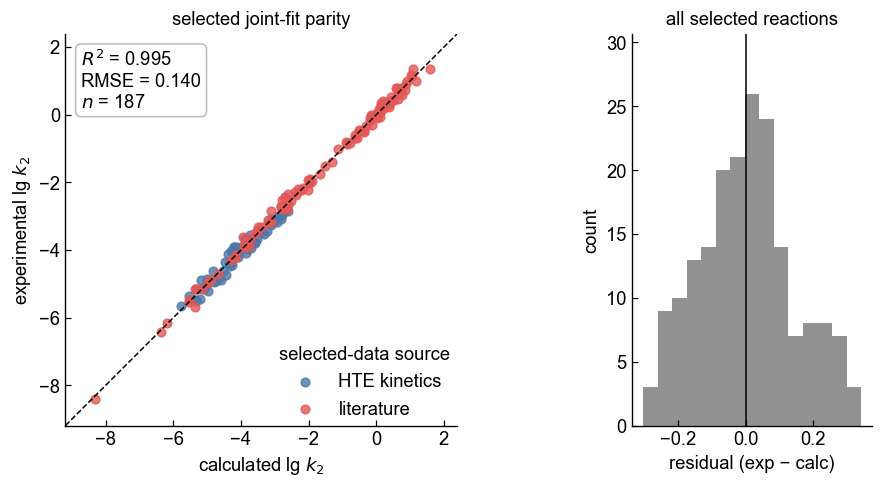

,source,n,rmse,bias
0,hte_kinetics,71,0.172,-0.027
1,literature,116,0.117,0.016


Largest residuals:


,nucleophile,electrophile,source,lgk,lgk_calc,residual
131,n-methylimidazole,P7,literature,-3.602,-3.943,0.341
65,cyclohexylamine,P9,hte_kinetics,-4.878,-5.189,0.311
69,imidazole,P9,hte_kinetics,-3.899,-4.210,0.311
186,imidazole,ATP,literature,-5.674,-5.368,-0.305
59,3-methoxypyridine,P9,hte_kinetics,-4.738,-4.436,-0.302
58,4-ethylpyridine,P9,hte_kinetics,-4.880,-4.579,-0.301
5,3-methoxypyridine,P5,hte_kinetics,-3.913,-4.200,0.286
135,3-methoxypyridine,P8,literature,-2.836,-3.117,0.282
174,4-dimethylaminopyridine,isoquinoliniumphosphate,literature,1.358,1.086,0.272
54,piperazine,P8,hte_kinetics,-2.431,-2.701,0.270


In [7]:
fig, ax = plt.subplots(1, 2, figsize=(9.4, 4.6), gridspec_kw=dict(width_ratios=[3.2, 1]))
source_palette = {"hte_kinetics": "#4C78A8", "literature": "#E45756"}
parity_plot(fitted, ax[0], by="source", palette=source_palette,
            label_fmt=lambda s: "HTE kinetics" if s == "hte_kinetics" else "literature",
            legend_title="selected-data source")
ax[0].set_title("selected joint-fit parity")

counts, _, _ = ax[1].hist(fitted["residual"], bins=15, color="#7F7F7F", alpha=0.85)
ax[1].axvline(0, color="k", lw=1)
ax[1].set_ylim(0, max(counts) * 1.18 if len(counts) else 1)
ax[1].set_xlabel("residual (exp \u2212 calc)"); ax[1].set_ylabel("count")
ax[1].set_title("all selected reactions")
_despine(ax[1])
plt.tight_layout(); plt.show()

# Fit quality resolved by source. The parameters are shared, so a difference here reflects the data rather than the model.
source_fit_metrics = (fitted.groupby("source")
                      .agg(n=("lgk", "size"),
                           rmse=("residual", lambda x: np.sqrt(np.mean(x * x))),
                           bias=("residual", "mean"))
                      .reset_index())
display(source_fit_metrics.round(3))

print("Largest residuals:")
display(fitted.assign(abs_res=fitted["residual"].abs())
        .sort_values("abs_res", ascending=False)
        [["nucleophile", "electrophile", "source", "lgk", "lgk_calc", "residual"]]
        .head(10).round(3))


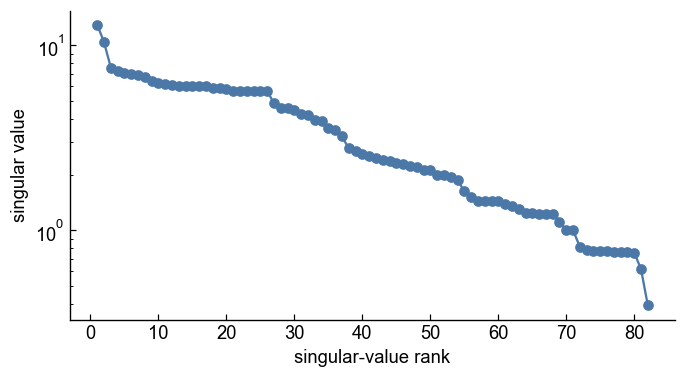

condition number ~ 32.9


In [8]:
# Numerical identifiability — singular values of the Jacobian
_, _, _, res = fit_lfer(core)
sv = np.linalg.svd(res.jac, compute_uv=False)
fig, ax = plt.subplots(figsize=(6.4, 3.6))
ax.semilogy(np.arange(1, len(sv) + 1), sv, "o-", color="#4C78A8")
ax.set_xlabel("singular-value rank"); ax.set_ylabel("singular value")
_despine(ax)
plt.tight_layout(); plt.show()
print(f"condition number ~ {sv[0]/sv[-1]:.1f}")


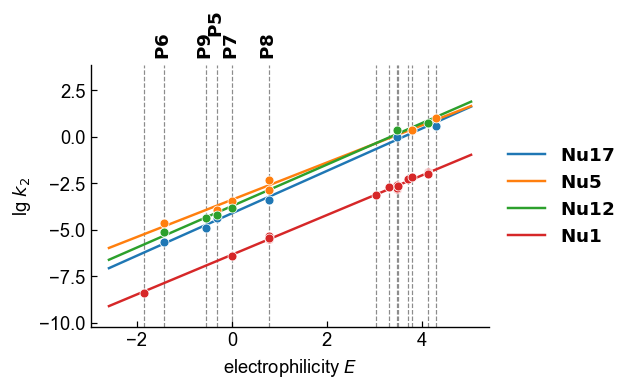

In [9]:
plot_lgk_vs_E(core, params, CONFIG.LGK_VS_E_NUCLEOPHILES, label_all_electrophiles=False)
plt.tight_layout(rect=[0, 0, 1, 0.80]); plt.show()

## 5. Bayesian bootstrap uncertainty

**Rubin's Bayesian bootstrap**: each selected reaction gets a weight from
$\mathrm{Dirichlet}(1,\dots,1)$ (mean-1 rescaled) and the joint LFER is refit by weighted least
squares, repeated `N_BOOT` times. Every observation keeps positive weight in every replicate, so no
species ever drops out. Medians and 2.5/97.5 % quantiles are reported and propagated through every subsequent attachment and prediction.

In [10]:
def bayesian_bootstrap(data, cfg=CONFIG, n_boot=None, seed=None,
                       anchor_nuc=None, anchor_elec=None):
    n_boot = n_boot or cfg.N_BOOT
    seed = cfg.BOOT_SEED if seed is None else seed
    d = data.reset_index(drop=True); n = len(d); rng = np.random.default_rng(seed)
    draws, fails = [], 0
    for b in range(n_boot):
        w = rng.dirichlet(np.ones(n)) * n
        try:
            p, _, m, _ = fit_lfer(d, cfg, weights=w, anchor_nuc=anchor_nuc, anchor_elec=anchor_elec)
            if not m["success"]:
                fails += 1; continue
            p["bootstrap_id"] = b; draws.append(p)
        except Exception:
            fails += 1
    boot = pd.concat(draws, ignore_index=True)
    summ = (boot.groupby(["type", "species", "parameter"])["estimate"]
            .agg(median="median", lo95=lambda x: np.quantile(x, .025), hi95=lambda x: np.quantile(x, .975),
                 sd="std", n_boot="count").reset_index())
    summ["ci_width"] = summ["hi95"] - summ["lo95"]
    return boot, summ, dict(requested=n_boot, successful=boot["bootstrap_id"].nunique(), failed=fails)

boot, boot_summary, boot_diag = bayesian_bootstrap(core)
print(boot_diag)
boot_summary = boot_summary.merge(params.rename(columns={"estimate": "point"}),
                                  on=["type", "species", "parameter"], how="left")
display(boot_summary.sort_values(["type", "parameter", "species"]).round(3))


{'requested': 600, 'successful': 600, 'failed': 0}


,type,species,parameter,median,lo95,hi95,sd,n_boot,ci_width,point
0,electrophile,"3,4-lutidiniumphosphate",E,3.044,2.856,3.255,0.101,600,0.399,3.038
1,electrophile,"3,5-dimethylpyridiniumphosphate",E,3.323,3.073,3.544,0.123,600,0.471,3.319
2,electrophile,3-Methoxypyridiniumphosphate,E,4.312,4.059,4.545,0.119,600,0.486,4.302
3,electrophile,3-Methylpyridiniumphosphate,E,3.723,3.475,3.979,0.133,600,0.505,3.715
4,electrophile,3-aminopyridiniumphosphate,E,3.517,3.289,3.744,0.119,600,0.455,3.509
...,...,...,...,...,...,...,...,...,...,...
75,nucleophile,pyridine,s,0.969,0.900,1.037,0.035,600,0.137,0.966
77,nucleophile,pyrrolidine,s,0.868,0.704,0.943,0.059,600,0.240,0.873
79,nucleophile,semicarbazide,s,0.975,0.913,1.056,0.037,600,0.143,0.973
81,nucleophile,triethylenediamine,s,0.906,0.837,0.994,0.040,600,0.157,0.910


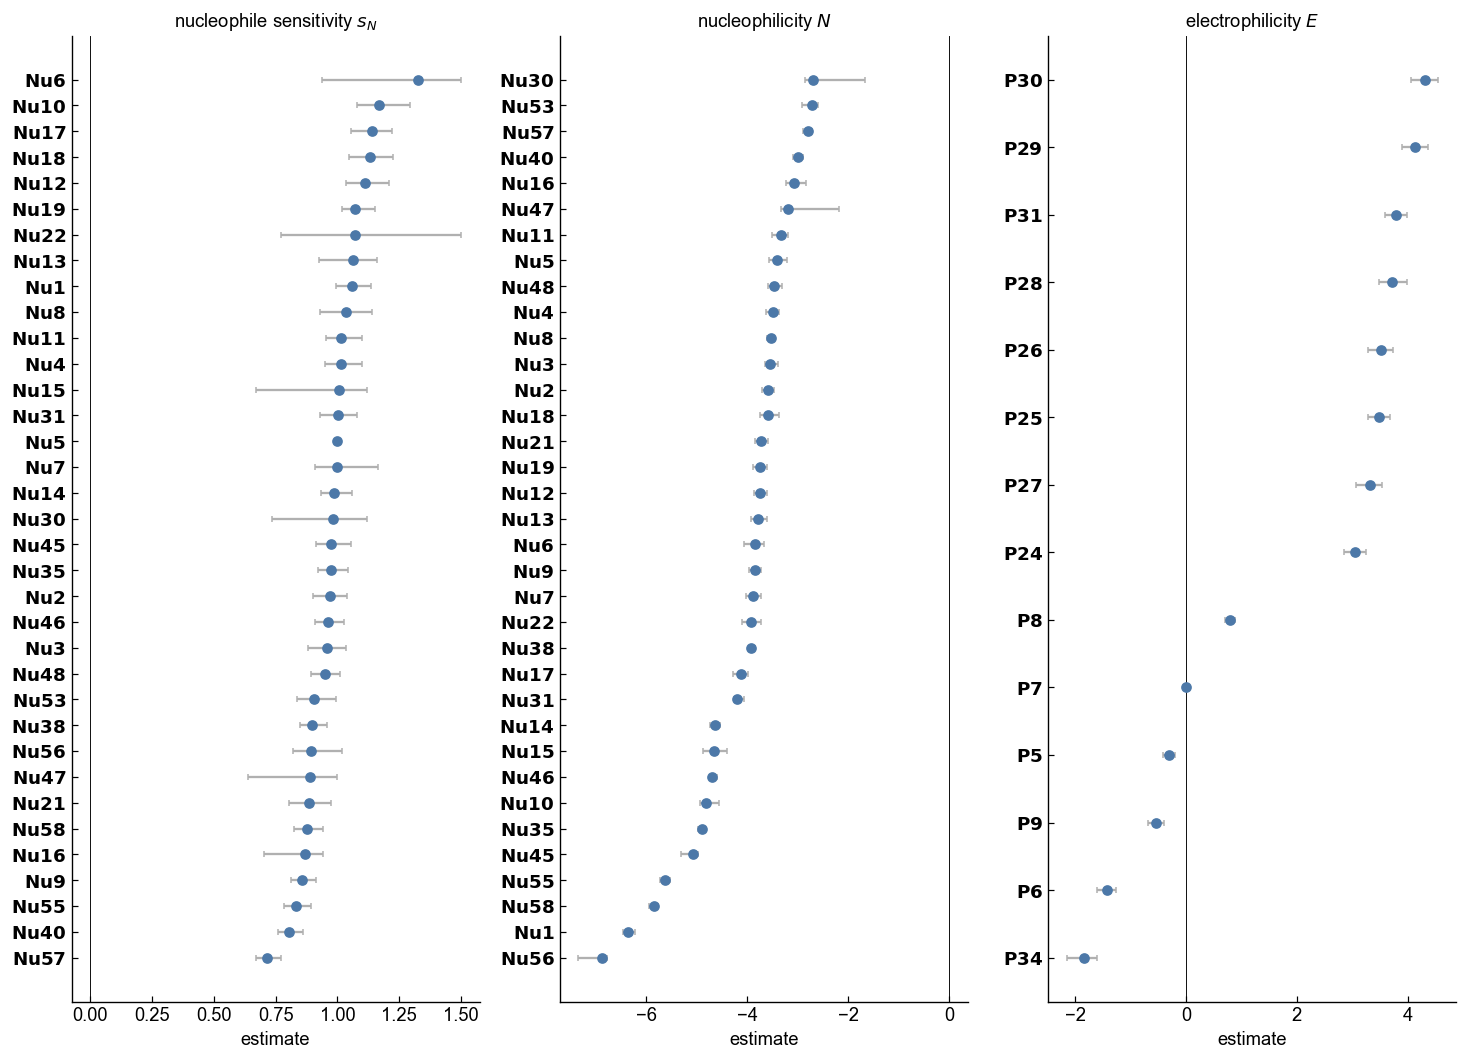

In [11]:
# Bayesian-bootstrap parameter interval plots, separated by parameter family.
def parameter_interval_panel(summary, parameter, ax, title):
    ps = summary[summary["parameter"] == parameter].copy()
    ps["id_label"] = [species_id(sp, role) for sp, role in zip(ps["species"], ps["type"])]
    ps = ps.sort_values("median").reset_index(drop=True)
    ypos = np.arange(len(ps))
    ax.errorbar(ps["median"], ypos, xerr=[ps["median"] - ps["lo95"], ps["hi95"] - ps["median"]],
                fmt="o", color="#4C78A8", ecolor="#B0B0B0", capsize=2)
    ax.set_yticks(ypos); ax.set_yticklabels(ps["id_label"])
    for tick in ax.get_yticklabels():
        tick.set_fontweight("bold")
    ax.axvline(0, color="k", lw=0.6)
    ax.set_xlabel("estimate")
    _despine(ax)
    ax.set_title(title)
    return ps

fig, axes = plt.subplots(1, 3, figsize=(13.5, max(4.5, 0.28 * boot_summary.query("parameter in ['N', 's']").species.nunique())))
parameter_interval_panel(boot_summary, "s", axes[0], "nucleophile sensitivity $s_N$")
parameter_interval_panel(boot_summary, "N", axes[1], "nucleophilicity $N$")
parameter_interval_panel(boot_summary, "E", axes[2], "electrophilicity $E$")
plt.tight_layout(); plt.show()


In [12]:
# Prediction helpers + global model dispersion
model_bias = fitted["residual"].mean()
model_dispersion = np.sqrt(np.mean((fitted["residual"] - model_bias)**2))
print(f"model bias={model_bias:+.3f}  dispersion={model_dispersion:.3f}  (95% ~ {1.96*model_dispersion:.2f} lg units)")

def boot_prediction(boot_df, nucleophile, electrophile):
    vals = []
    for _, g in boot_df.groupby("bootstrap_id"):
        p = _param_lookup(g)
        try:
            vals.append(predict_lgk(p, nucleophile, electrophile))
        except KeyError:
            pass
    return np.asarray(vals, float)


model bias=-0.000  dispersion=0.140  (95% ~ 0.28 lg units)


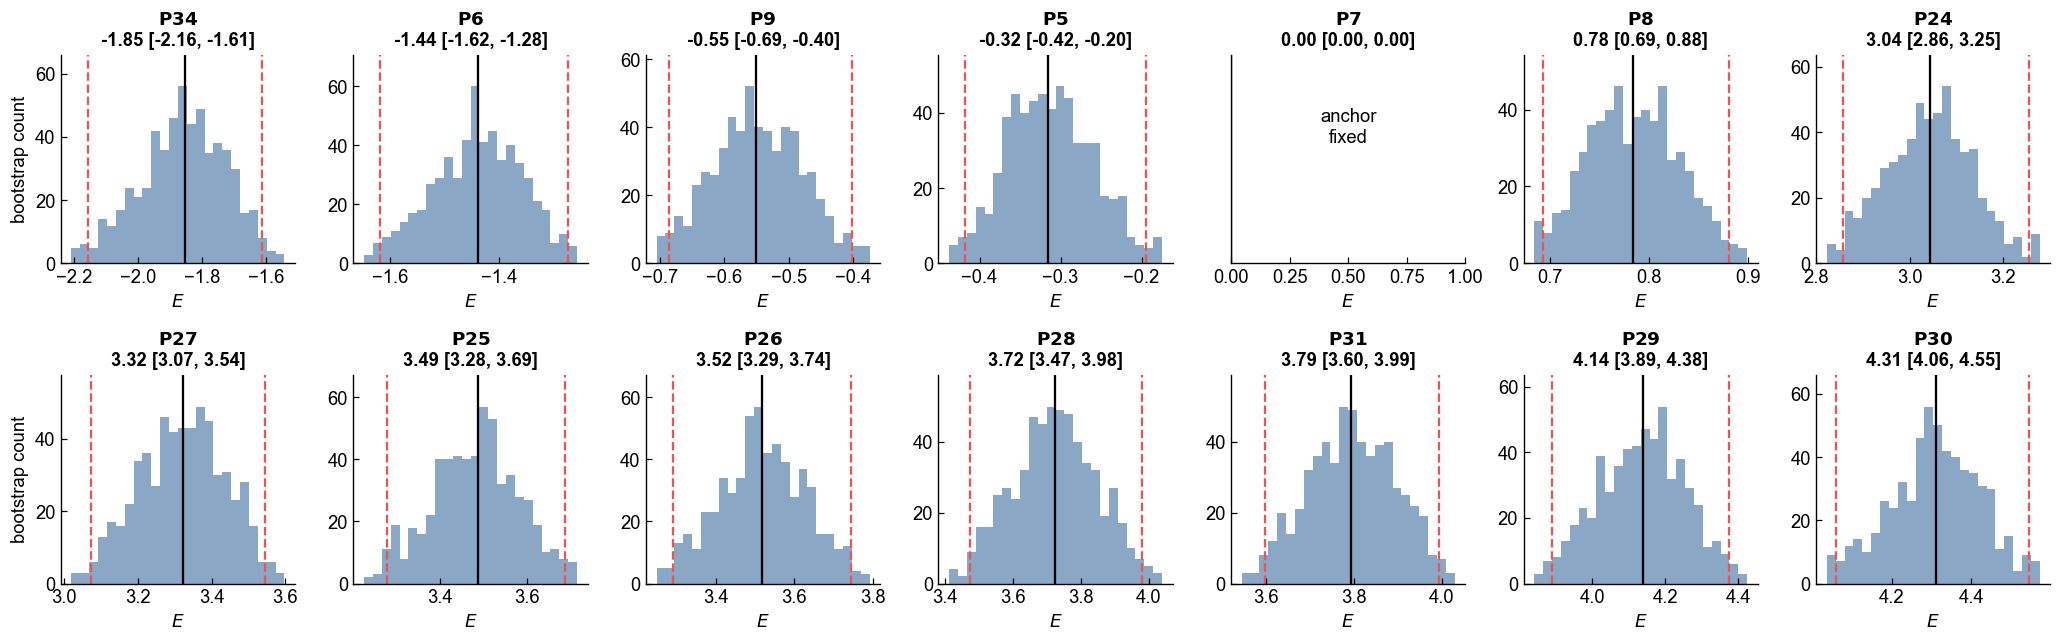

In [13]:
# Bootstrap distributions of the selected-system electrophilicity parameters E.
elecs = sorted(core.electrophile.unique(), key=lambda e: _param_lookup(params)[("electrophile", e, "E")])
ncols = math.ceil(len(elecs) / 2)
fig, axes = plt.subplots(2, ncols, figsize=(2.7 * ncols, 6.0), squeeze=False)

for ax, e in zip(axes.ravel(), elecs):
    x = boot.query("type=='electrophile' and species==@e and parameter=='E'")["estimate"].to_numpy(float)
    lo, hi = np.quantile(x, [.025, .975])
    med = np.median(x)
    if np.std(x) <= 1e-12:
        # the anchor is fixed by convention, so its bootstrap distribution is degenerate
        ax.axvline(med, color="k", lw=1.5)
        ax.text(.5, .58, "anchor\nfixed", transform=ax.transAxes, ha="center")
        ax.set_ylim(0, 1); ax.set_yticks([])
    else:
        trimmed = x[(x > np.quantile(x, .01)) & (x < np.quantile(x, .99))]
        counts, _, _ = ax.hist(trimmed, bins=24, color="#4C78A8", alpha=.65)
        ax.set_ylim(0, max(counts) * 1.18)
        ax.axvline(med, color="k")
        ax.axvline(lo, color="#E45756", ls="--")
        ax.axvline(hi, color="#E45756", ls="--")
    ax.set_title(f"{electrophile_id(e)}\n{med:.2f} [{lo:.2f}, {hi:.2f}]", fontweight="bold")
    ax.set_xlabel("$E$")
    _despine(ax)

for ax in axes.ravel()[len(elecs):]:
    ax.set_visible(False)
for ax in axes[:, 0]:
    ax.set_ylabel("bootstrap count")
plt.tight_layout(); plt.show()


raw-but-excluded reaction pairs marked with open circles: 17


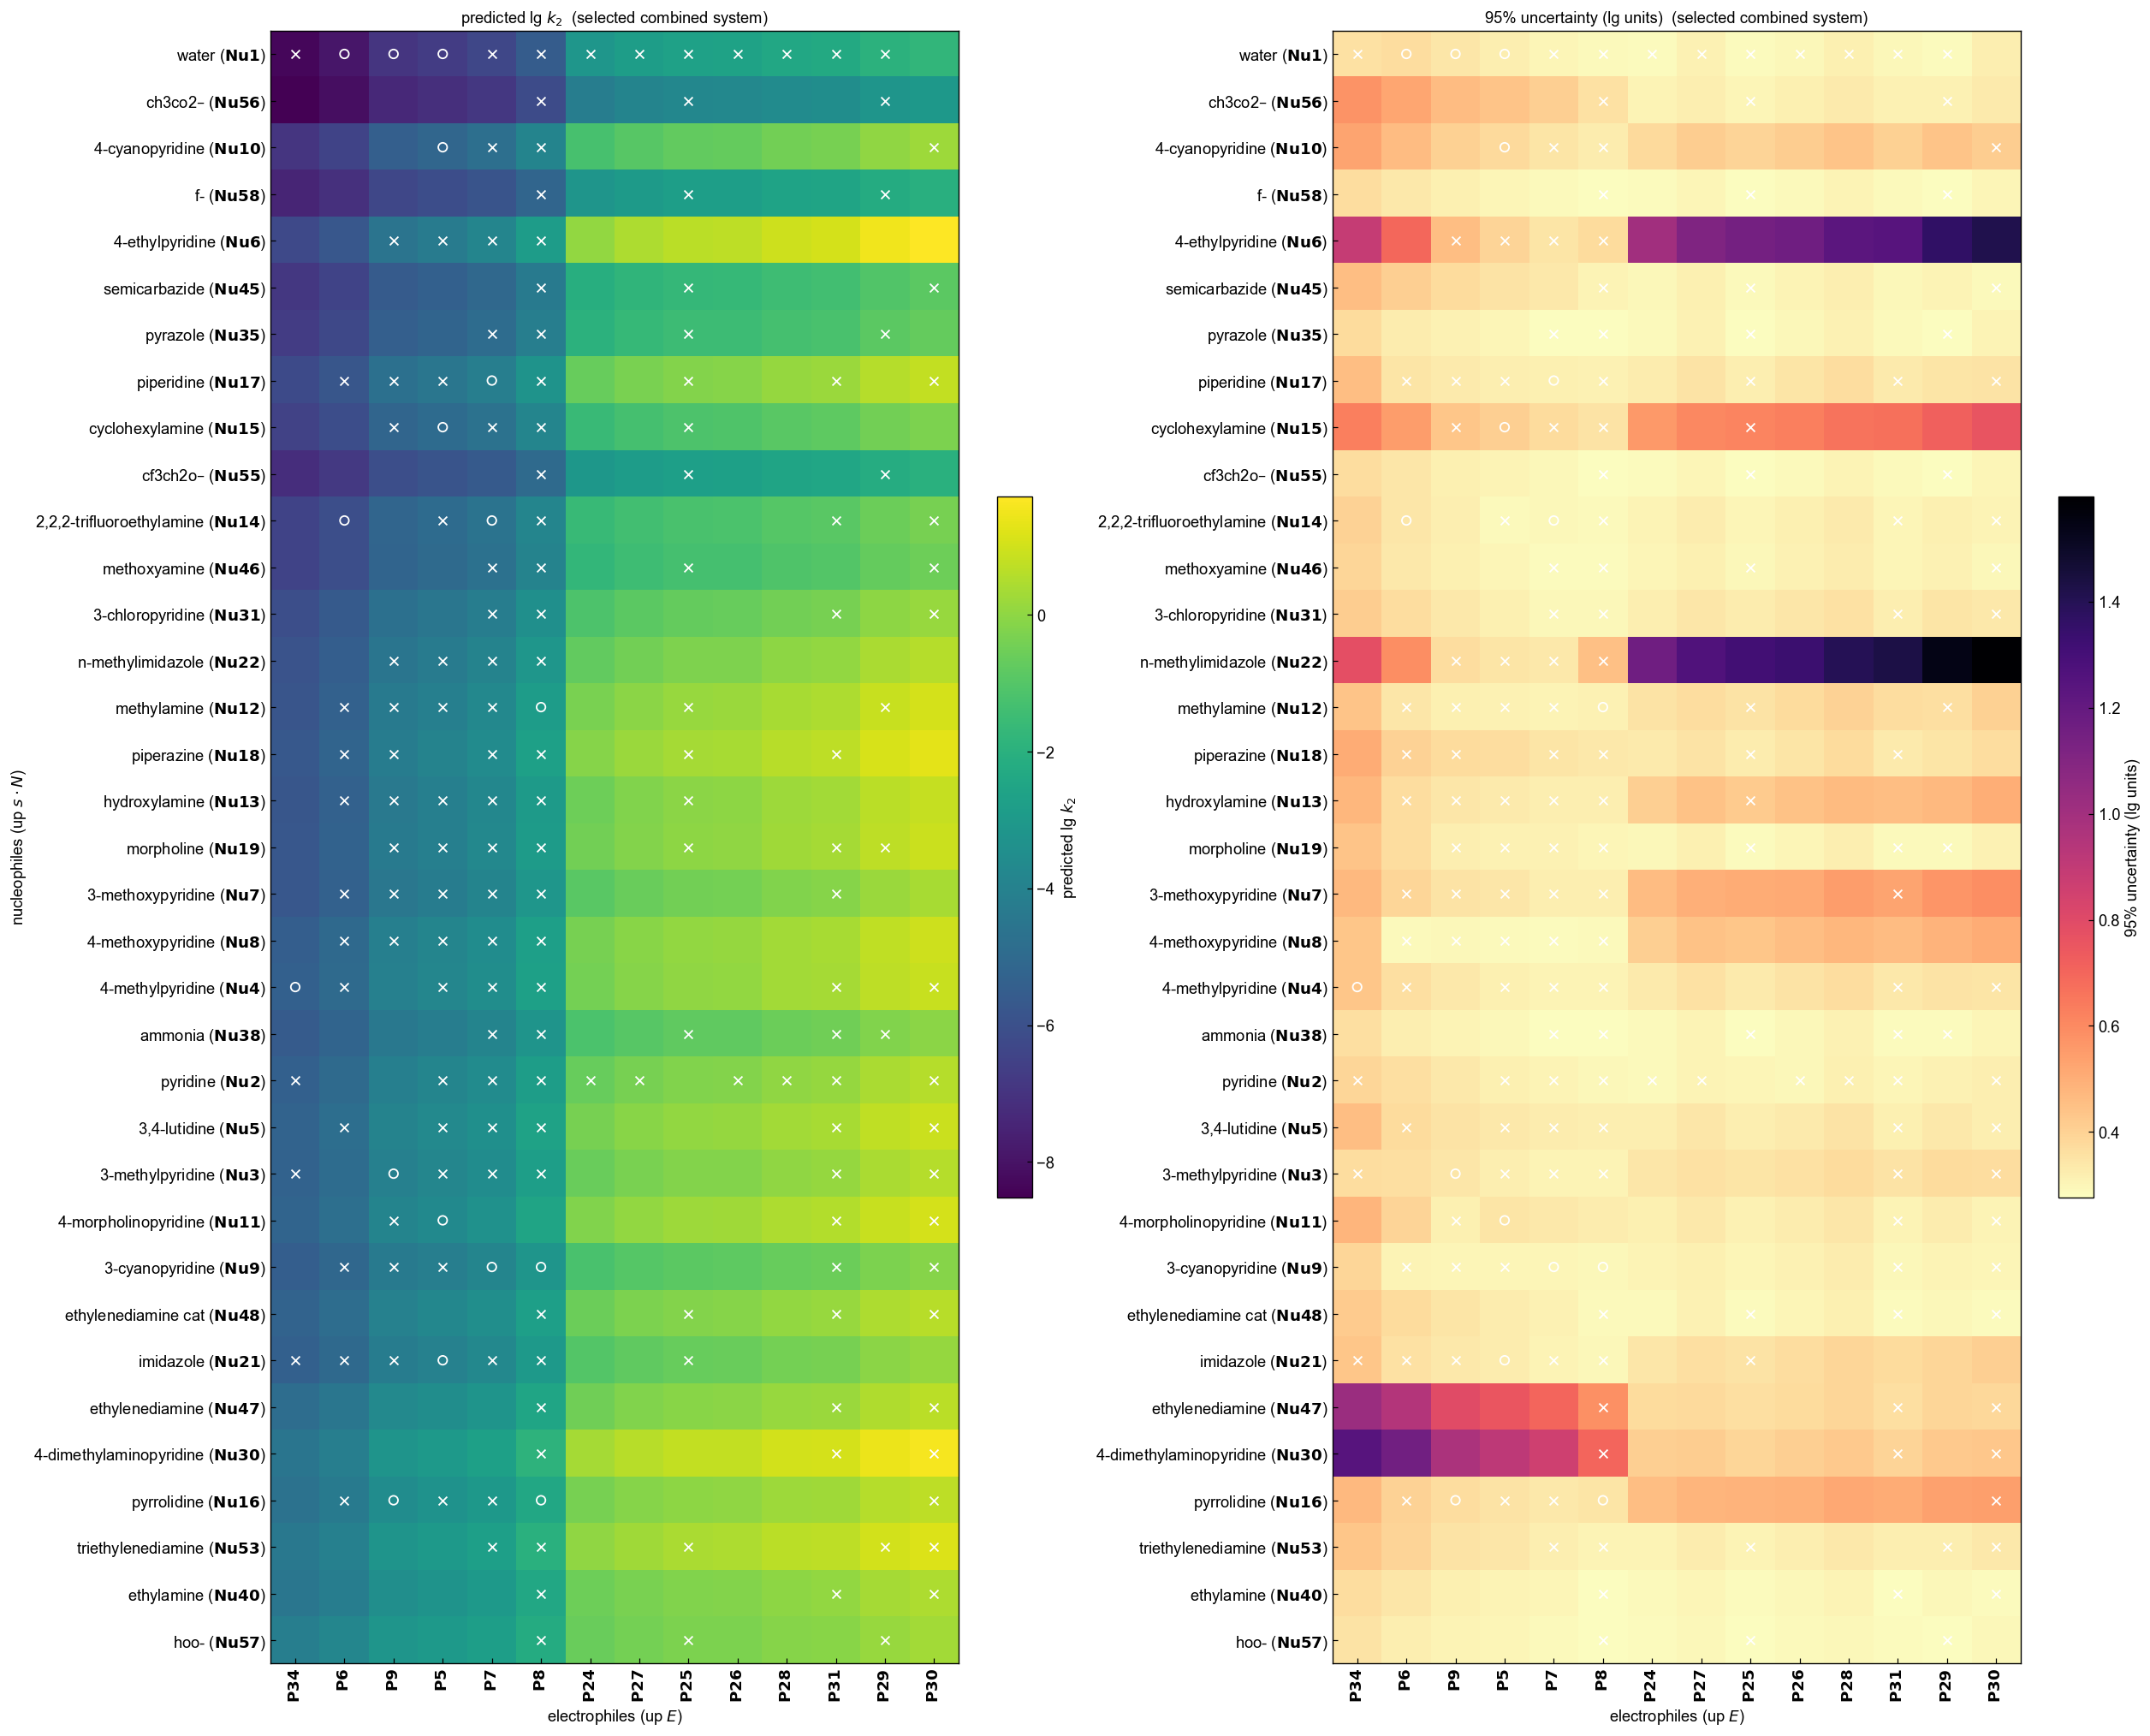

In [14]:
# Prediction-uncertainty & predicted-lg k heat maps (selected combined dataset)
def sort_orders(params):
    p = _param_lookup(params)
    elecs = sorted({s for (t, s, q) in p if t == "electrophile"})
    nucs  = sorted({s for (t, s, q) in p if t == "nucleophile"})
    E_order = sorted(elecs, key=lambda e: p[("electrophile", e, "E")])
    N_order = sorted(nucs, key=lambda n: p[("nucleophile", n, "s")] * p[("nucleophile", n, "N")])
    return N_order, E_order

def heatmaps(params, boot_df, observed_used, observed_excluded=frozenset(),
             disp=None, title_suffix="", uncertainty_mask_threshold=5.0):
    disp = model_dispersion if disp is None else disp
    p = _param_lookup(params); N_order, E_order = sort_orders(params)
    K = np.full((len(N_order), len(E_order)), np.nan); U = K.copy()
    for i, n in enumerate(N_order):
        for j, e in enumerate(E_order):
            K[i, j] = predict_lgk(p, n, e)
            pd_ = boot_prediction(boot_df, n, e)
            if len(pd_) >= 5:
                U[i, j] = 1.96 * np.sqrt(disp**2 + np.nanvar(pd_, ddof=1))
    high_uncertainty = np.isfinite(U) & (U > uncertainty_mask_threshold)
    fig, axes = plt.subplots(1, 2, figsize=(1.0*len(E_order)+9, 0.46*len(N_order)+2.5))
    for ax, M, lab, cmap in [(axes[0], K, "predicted lg $k_2$", "viridis"),
                             (axes[1], U, "95% uncertainty (lg units)", "magma_r")]:
        cmap_obj = plt.get_cmap(cmap).copy()
        cmap_obj.set_bad("lightgrey")
        im = ax.imshow(np.ma.masked_where(high_uncertainty, M), aspect="auto", cmap=cmap_obj)
        fig.colorbar(im, ax=ax, label=lab, fraction=0.046)
        for i, n in enumerate(N_order):
            for j, e in enumerate(E_order):
                if (n, e) in observed_used:
                    ax.scatter(j, i, marker="x", s=42, c="white", linewidths=1.2)
                elif (n, e) in observed_excluded:
                    ax.scatter(j, i, marker="o", s=46, facecolors="none", edgecolors="white", linewidths=1.2)
        ax.set_xticks(range(len(E_order))); ax.set_xticklabels([electrophile_id(e) for e in E_order], rotation=90)
        ax.set_yticks(range(len(N_order))); ax.set_yticklabels([nucleophile_name_id(n) for n in N_order])
        for tick in ax.get_xticklabels():
            tick.set_fontweight("bold")
        ax.set_xlabel("electrophiles (up $E$)"); ax.set_title(lab + title_suffix)
    axes[0].set_ylabel(r"nucleophiles (up $s\cdot N$)")
    plt.tight_layout(); plt.show()

# Used = reactions retained in the combined fit; open circles denote raw combined-system
# reaction pairs for the selected species that were removed by automated selection.
core_species_nuc = set(core.nucleophile); core_species_elec = set(core.electrophile)
observed_used = set(zip(core["nucleophile"], core["electrophile"]))
studied = combined_raw[combined_raw.nucleophile.isin(core_species_nuc) & combined_raw.electrophile.isin(core_species_elec)]
observed_excluded = set(zip(studied["nucleophile"], studied["electrophile"])) - observed_used
print(f"raw-but-excluded reaction pairs marked with open circles: {len(observed_excluded)}")
heatmaps(params, boot, observed_used, observed_excluded, title_suffix="  (selected combined system)")


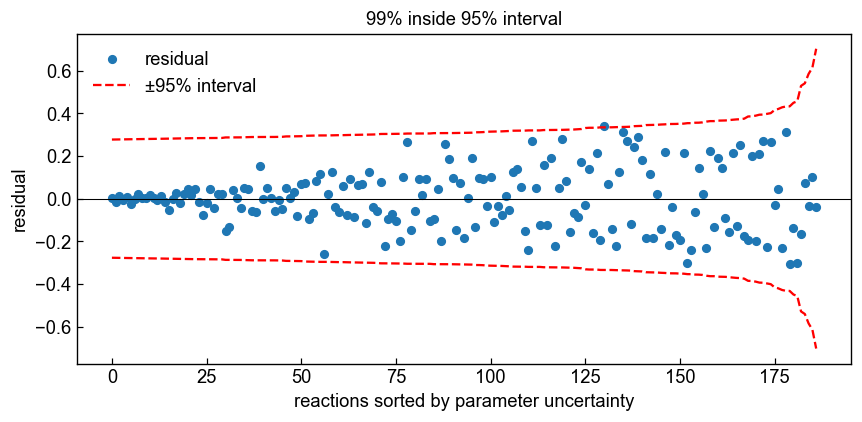

In [15]:
# Calibration: fraction of observed residuals inside the bootstrap 95% prediction interval
rows = []
for _, r in fitted.iterrows():
    pd_ = boot_prediction(boot, r["nucleophile"], r["electrophile"])
    beta = np.nanstd(pd_, ddof=1) if len(pd_) > 1 else 0.0
    U95 = 1.96 * np.sqrt(model_dispersion**2 + beta**2)
    rows.append((r["residual"], beta, U95, abs(r["residual"]) <= U95))
cal = pd.DataFrame(rows, columns=["residual", "beta", "U95", "inside"]).sort_values("beta").reset_index(drop=True)
x = np.arange(len(cal))
plt.figure(figsize=(8, 4))
plt.scatter(x, cal["residual"], s=25, label="residual")
plt.plot(x, cal["U95"], "r--", label="±95% interval"); plt.plot(x, -cal["U95"], "r--")
plt.axhline(0, color="k", lw=0.7)
plt.xlabel("reactions sorted by parameter uncertainty"); plt.ylabel("residual")
plt.title(f"{100*cal['inside'].mean():.0f}% inside 95% interval"); plt.legend(frameon=False)
plt.tight_layout(); plt.show()


## 6. Placing the species discarded during selection

The LFER parametrized above defines a fixed reference scale, on which all points discarded above are testd for being added back in. 
Discarded electrophiles are estimated first from the selected nucleophiles they reacted with: estimates resting on at least two distinct
nucleophiles extend the usable $E_\mathrm{P}$ scale, single-nucleophile estimates are report-only.

Discarded nucleophiles are then fitted against the selected plus reliably attached electrophiles; pyridines follow the coverage-dependent mean-$s_\mathrm{N,P}$ rule, and a freely fitted
$s_\mathrm{N,P}$ at a bound leads to rejection. Bootstrap draws propagate the selected-system uncertainty through every attachment.

In [16]:
def core_pyridine_s_reference(ref_nuc, cfg=CONFIG):
    """Mean and central interval of selected-system pyridine sensitivities."""
    mask = ref_nuc.index.to_series().map(lambda x: is_pyridine(x, cfg))
    vals = ref_nuc.loc[mask, "s"].dropna().to_numpy(float)
    if len(vals) == 0:
        return dict(mean=np.nan, lo=np.nan, hi=np.nan, n=0)
    if len(vals) >= 4:
        lo, hi = np.quantile(vals, [0.10, 0.90])
    else:
        sd = np.std(vals, ddof=1) if len(vals) > 1 else 0.0
        lo, hi = np.mean(vals) - 2 * sd, np.mean(vals) + 2 * sd
    return dict(mean=float(np.mean(vals)), lo=float(max(CONFIG.S_BOUNDS[0], lo)),
                hi=float(min(CONFIG.S_BOUNDS[1], hi)), n=int(len(vals)))


def _fit_fixed_E_group(g, cfg=CONFIG, fixed_s=None):
    x = g["E"].to_numpy(float)
    y = g["lgk"].to_numpy(float)
    n_electrophiles = int(g["E"].nunique())
    if fixed_s is None and n_electrophiles < 2:
        return None
    if fixed_s is not None:
        s = float(fixed_s)
        N = float(np.mean(y - s * x))
    else:
        def residual(v):
            return v[0] * x + v[1] - y
        opt = least_squares(
            residual, [np.clip(1.0, *cfg.S_BOUNDS), np.mean(y)],
            bounds=([cfg.S_BOUNDS[0], cfg.N_BOUNDS[0]],
                    [cfg.S_BOUNDS[1], cfg.N_BOUNDS[1]]),
            method="trf",
        )
        s, N = map(float, opt.x)
    calc = s * x + N
    resid = y - calc
    return dict(
        N=N, s=s, n_reactions=len(g), n_electrophiles=n_electrophiles,
        rmse=float(np.sqrt(np.mean(resid**2))), calc=calc, resid=resid,
        s_at_lower_bound=bool(s <= cfg.S_BOUNDS[0] + 1e-4),
        s_at_upper_bound=bool(s >= cfg.S_BOUNDS[1] - 1e-4),
    )


def _pyridine_decision(nucleophile, n_electrophiles, free_fit, pyr_ref, cfg=CONFIG):
    if not is_pyridine(nucleophile, cfg):
        status = ("validated free fit (>=3 E)" if n_electrophiles >= cfg.MIN_ELECTROPHILES
                  else "bounded low-coverage fit")
        return dict(use_fixed_s=False, method="bounded_sN_fit", status=status)
    if not np.isfinite(pyr_ref["mean"]):
        return dict(use_fixed_s=False, method="bounded_sN_fit",
                    status="pyridine reference unavailable; free bounded fit")
    if n_electrophiles < cfg.MIN_ELECTROPHILES:
        return dict(use_fixed_s=True, method="fixed_selected_pyridine_mean_s",
                    status=f"pyridine <3 E; s fixed to selected-system mean ({pyr_ref['mean']:.3f})")
    if n_electrophiles >= 4:
        return dict(use_fixed_s=False, method="bounded_sN_fit", status="pyridine >=4 E; free bounded fit")
    if (free_fit is not None and pyr_ref["lo"] <= free_fit["s"] <= pyr_ref["hi"]
            and not free_fit["s_at_lower_bound"] and not free_fit["s_at_upper_bound"]):
        return dict(use_fixed_s=False, method="bounded_sN_fit",
                    status=("pyridine 3 E; free s within selected-pyridine interval "
                            f"[{pyr_ref['lo']:.3f}, {pyr_ref['hi']:.3f}]"))
    s_txt = "nan" if free_fit is None else f"{free_fit['s']:.3f}"
    return dict(use_fixed_s=True, method="fixed_selected_pyridine_mean_s",
                status=("pyridine 3 E; free s=" + s_txt + " outside selected-pyridine interval "
                        f"[{pyr_ref['lo']:.3f}, {pyr_ref['hi']:.3f}], fixed to mean ({pyr_ref['mean']:.3f})"))


def place_discarded_nucleophiles(data, E_series, selected_nucleophiles, cfg=CONFIG):
    """Place every non-selected nucleophile on the fixed selected/reliably-attached E scale."""
    usable = data[data["electrophile"].isin(E_series.index)].copy()
    usable["E"] = usable["electrophile"].map(E_series)
    pyr_ref = core_pyridine_s_reference(ref_nuc, cfg)
    all_discarded = sorted(set(data["nucleophile"]) - set(selected_nucleophiles))
    rows, fitted_rows = [], []
    for nucleophile in all_discarded:
        g = usable[usable["nucleophile"] == nucleophile].copy()
        n_electrophiles = int(g["E"].nunique()) if len(g) else 0
        base = dict(nucleophile=nucleophile, n_reactions=len(g), n_electrophiles=n_electrophiles)
        free_fit = _fit_fixed_E_group(g, cfg=cfg) if len(g) else None
        fixed_fit = (_fit_fixed_E_group(g, cfg=cfg, fixed_s=pyr_ref["mean"])
                     if len(g) and is_pyridine(nucleophile, cfg) and np.isfinite(pyr_ref["mean"])
                     else None)
        decision = _pyridine_decision(nucleophile, n_electrophiles, free_fit, pyr_ref, cfg)
        fit = fixed_fit if decision["use_fixed_s"] else free_fit
        if fit is None:
            rows.append(dict(**base, N=np.nan, s=np.nan, rmse=np.nan, placed=False, rejected=False,
                             validated=False, placement_method="not_placed",
                             status="insufficient coverage: need >=2 distinct E (or pyridine mean-s placement)",
                             reject_reason=""))
            continue
        s_is_fitted = not decision["use_fixed_s"]
        if cfg.REJECT_S_AT_BOUNDS and s_is_fitted and (fit["s_at_lower_bound"] or fit["s_at_upper_bound"]):
            side = "lower" if fit["s_at_lower_bound"] else "upper"
            reason = f"fitted s at {side} bound ({fit['s']:.2f})"
            rows.append(dict(**base, N=fit["N"], s=fit["s"], rmse=fit["rmse"], placed=False,
                             rejected=True, validated=False, placement_method="rejected_s_at_bound",
                             status=f"rejected: {reason}; parameters not identifiable", reject_reason=reason))
            continue
        rows.append(dict(**base, N=fit["N"], s=fit["s"], rmse=fit["rmse"], placed=True,
                         rejected=False, validated=n_electrophiles >= cfg.MIN_ELECTROPHILES,
                         placement_method=decision["method"], status=decision["status"], reject_reason="",
                         pyridine_s_ref_mean=pyr_ref["mean"]))
        fitted_rows.append(g.assign(lgk_calc=fit["calc"], residual=fit["resid"],
                                    placement_method=decision["method"],
                                    validated=n_electrophiles >= cfg.MIN_ELECTROPHILES,
                                    status=decision["status"]))
    table = pd.DataFrame(rows)
    fitted = (pd.concat(fitted_rows, ignore_index=True) if fitted_rows
              else pd.DataFrame(columns=["lgk", "lgk_calc", "residual"]))
    return table, fitted, pyr_ref


def estimate_discarded_electrophiles(data, selected_nuc, selected_electrophiles, cfg=CONFIG):
    """Estimate every non-selected E using only jointly selected nucleophile parameters."""
    candidates = sorted(set(data["electrophile"]) - set(selected_electrophiles))
    rows, detail = [], []
    for electrophile in candidates:
        raw_group = data[data["electrophile"] == electrophile].copy()
        group = raw_group[raw_group["nucleophile"].isin(selected_nuc.index)].copy()
        base = dict(electrophile=electrophile, n_raw_reactions=len(raw_group),
                    n_reactions=len(group), n_nucleophiles=group["nucleophile"].nunique())
        if len(group) == 0:
            rows.append(dict(**base, E=np.nan, rmse=np.nan, placed=False, reliable=False,
                             export_status="not placed", status="no reaction with a selected nucleophile"))
            continue
        s = selected_nuc.loc[group["nucleophile"], "s"].to_numpy(float)
        N = selected_nuc.loc[group["nucleophile"], "N"].to_numpy(float)
        y = group["lgk"].to_numpy(float)
        if np.sum(s**2) < 1e-9:
            rows.append(dict(**base, E=np.nan, rmse=np.nan, placed=False, reliable=False,
                             export_status="not placed", status="numerically undefined E estimate"))
            continue
        E = float(np.sum(s * (y - N)) / np.sum(s**2))
        residual = y - (s * E + N)
        reliable = base["n_nucleophiles"] >= cfg.MIN_NUC_FOR_NEW_E
        rows.append(dict(**base, E=E, rmse=float(np.sqrt(np.mean(residual**2))), placed=True,
                         reliable=reliable,
                         export_status=("reliable" if reliable else "single-nucleophile definition"),
                         status=("reliable >=2 selected nucleophiles" if reliable
                                 else "reported only; not used for nucleophile placement")))
        detail.append(group.assign(E_fit=E, lgk_calc=s * E + N, residual=residual,
                                   n_nucleophiles=base["n_nucleophiles"],
                                   prediction_origin="discarded-system E on selected combined scale",
                                   validation_class=("reliable" if reliable else "single-nucleophile definition")))
    columns = ["electrophile", "n_raw_reactions", "n_reactions", "n_nucleophiles", "E", "rmse",
               "placed", "reliable", "export_status", "status"]
    table = pd.DataFrame(rows, columns=columns).sort_values("electrophile").reset_index(drop=True)
    details = pd.concat(detail, ignore_index=True) if detail else pd.DataFrame()
    return table, details


def bootstrap_discarded_E(data, selected_boot, selected_electrophiles, cfg=CONFIG):
    """Propagate selected-system bootstrap uncertainty and reaction-level Dirichlet weights into E."""
    candidate_set = set(data["electrophile"]) - set(selected_electrophiles)
    candidates = sorted(candidate_set & set(discarded_E.loc[discarded_E["placed"], "electrophile"]))
    rng, rows = np.random.default_rng(cfg.BOOT_SEED + 11), []
    for bootstrap_id, bp in selected_boot.groupby("bootstrap_id"):
        bn = bp.query("type == 'nucleophile'").pivot(index="species", columns="parameter", values="estimate")
        for electrophile in candidates:
            group = data[(data["electrophile"] == electrophile) & data["nucleophile"].isin(bn.index)]
            if len(group) == 0:
                continue
            weights = rng.dirichlet(np.ones(len(group))) * len(group)
            s = bn.loc[group["nucleophile"], "s"].to_numpy(float)
            N = bn.loc[group["nucleophile"], "N"].to_numpy(float)
            y = group["lgk"].to_numpy(float)
            if np.sum(weights * s**2) <= 1e-9:
                continue
            rows.append(dict(bootstrap_id=bootstrap_id, electrophile=electrophile,
                             E=float(np.sum(weights * s * (y - N)) / np.sum(weights * s**2))))
    draws = pd.DataFrame(rows)
    summary = (draws.groupby("electrophile")["E"].agg(
        median="median", lo95=lambda x: np.quantile(x, .025), hi95=lambda x: np.quantile(x, .975),
        sd="std", n_boot="count").reset_index() if len(draws)
        else pd.DataFrame(columns=["electrophile", "median", "lo95", "hi95", "sd", "n_boot"]))
    return draws, summary


def _bootstrap_place_nucleophiles(placement_table, data, E_series, selected_nucleophiles,
                                  pyridine_s, bootstrap_id):
    rows = []
    for _, placed in placement_table[placement_table["placed"]].iterrows():
        nucleophile = placed["nucleophile"]
        if nucleophile in selected_nucleophiles:
            continue
        group = data[(data["nucleophile"] == nucleophile) & data["electrophile"].isin(E_series.index)].copy()
        if len(group) == 0:
            continue
        group["E"] = group["electrophile"].map(E_series)
        fixed_s = pyridine_s if placed["placement_method"] == "fixed_selected_pyridine_mean_s" else None
        fit = _fit_fixed_E_group(group, fixed_s=fixed_s)
        if fit is None:
            continue
        rows.extend([
            dict(bootstrap_id=bootstrap_id, type="nucleophile", species=nucleophile,
                 parameter="N", estimate=fit["N"]),
            dict(bootstrap_id=bootstrap_id, type="nucleophile", species=nucleophile,
                 parameter="s", estimate=fit["s"]),
        ])
    return rows


ref_nuc, ref_elec = param_table(params)
known_nuc, known_elec = set(ref_nuc.index), set(ref_elec.index)
selected_pyridine_s_ref = core_pyridine_s_reference(ref_nuc)
print(f"Selected-system pyridine s reference: mean={selected_pyridine_s_ref['mean']:.3f}, "
      f"interval=[{selected_pyridine_s_ref['lo']:.3f}, {selected_pyridine_s_ref['hi']:.3f}], "
      f"n={selected_pyridine_s_ref['n']}")

discarded_E, discarded_E_detail = estimate_discarded_electrophiles(combined_raw, ref_nuc, known_elec)
reportable_E = discarded_E[discarded_E["placed"]].copy()
reliable_E = reportable_E[reportable_E["reliable"]].copy()
boot_discarded_E, discarded_E_unc = bootstrap_discarded_E(combined_raw, boot, known_elec)
reportable_E = reportable_E.merge(discarded_E_unc, on="electrophile", how="left")

print(f"Discarded electrophiles: {len(reliable_E)} reliable E placements and "
      f"{int((reportable_E['export_status'] == 'single-nucleophile definition').sum())} "
      "single-nucleophile definitions (report only).")
display(reportable_E.round(3))

usable_E = pd.concat([ref_elec["E"], reliable_E.set_index("electrophile")["E"]])
usable_E = usable_E[~usable_E.index.duplicated()]
discarded_nuc, discarded_nuc_fitted, _ = place_discarded_nucleophiles(combined_raw, usable_E, known_nuc)
print("Discarded nucleophiles placed on the selected plus reliable-attached E scale:")
display(discarded_nuc.round(3))

attachment_boot_parts = [boot[["bootstrap_id", "type", "species", "parameter", "estimate"]].copy()]
e_rows, n_rows = [], []
reportable_E_names = set(reportable_E["electrophile"])
reliable_E_names = set(reliable_E["electrophile"])
for bootstrap_id, bp in boot.groupby("bootstrap_id"):
    bn = bp.query("type == 'nucleophile'").pivot(index="species", columns="parameter", values="estimate")
    be = bp.query("type == 'electrophile' and parameter == 'E'").set_index("species")["estimate"]
    pyr_mask = bn.index.to_series().map(is_pyridine)
    pyridine_s = float(bn.loc[pyr_mask, "s"].mean()) if pyr_mask.any() else selected_pyridine_s_ref["mean"]
    b_e = boot_discarded_E[(boot_discarded_E["bootstrap_id"] == bootstrap_id)
                           & boot_discarded_E["electrophile"].isin(reportable_E_names)]
    for _, row in b_e.iterrows():
        e_rows.append(dict(bootstrap_id=bootstrap_id, type="electrophile", species=row["electrophile"],
                           parameter="E", estimate=row["E"]))
    b_reliable_E = b_e[b_e["electrophile"].isin(reliable_E_names)].set_index("electrophile")["E"]
    b_usable_E = pd.concat([be, b_reliable_E])
    b_usable_E = b_usable_E[~b_usable_E.index.duplicated()]
    n_rows.extend(_bootstrap_place_nucleophiles(discarded_nuc, combined_raw, b_usable_E,
                                                 known_nuc, pyridine_s, bootstrap_id))
if e_rows:
    attachment_boot_parts.append(pd.DataFrame(e_rows))
if n_rows:
    attachment_boot_parts.append(pd.DataFrame(n_rows))
attachment_boot = pd.concat(attachment_boot_parts, ignore_index=True, sort=False).dropna(subset=["estimate"])
attachment_boot_summary = (attachment_boot.groupby(["type", "species", "parameter"])["estimate"].agg(
    median="median", lo95=lambda x: np.quantile(x, .025), hi95=lambda x: np.quantile(x, .975),
    sd="std", n_boot="count").reset_index())
attachment_boot_summary["ci_width"] = attachment_boot_summary["hi95"] - attachment_boot_summary["lo95"]

attachment_summary = pd.DataFrame([
    dict(group="selected combined system", n_species=len(ref_nuc) + len(ref_elec),
         n_parameters=len(params), note="joint E/N/s fit after automatic selection"),
    dict(group="discarded electrophiles", n_species=len(reportable_E), n_parameters=len(reportable_E),
         note="includes report-only single-nucleophile E definitions"),
    dict(group="discarded nucleophiles", n_species=int(discarded_nuc["placed"].sum()),
         n_parameters=int(2 * discarded_nuc["placed"].sum()),
         note="N,s on selected plus reliable attached E scale"),
])
display(attachment_summary)
print(f"Bootstrap rows for selected plus discarded-system parameters: {len(attachment_boot)}")


Selected-system pyridine s reference: mean=1.027, interval=[0.961, 1.152], n=12


Discarded electrophiles: 0 reliable E placements and 20 single-nucleophile definitions (report only).


,electrophile,n_raw_reactions,n_reactions,n_nucleophiles,E,rmse,placed,reliable,export_status,status,median,lo95,hi95,sd,n_boot
0,"2,4,6-trichlorophenylphosphate",1,1,1,-1.903,0.000,True,False,single-nucleophile definition,reported only; not used for nucleophile placement,-1.916,-2.141,-1.731,0.107,600
1,2-chloro-4-nitrophenylphosphate,1,1,1,-1.213,0.000,True,False,single-nucleophile definition,reported only; not used for nucleophile placement,-1.223,-1.410,-1.074,0.087,600
2,2-nitro-4-COMe-phenylphosphate,1,1,1,0.414,0.000,True,False,single-nucleophile definition,reported only; not used for nucleophile placement,0.409,0.289,0.500,0.055,600
3,2-nitro-4-chlorophenylphosphate,1,1,1,-1.055,0.000,True,False,single-nucleophile definition,reported only; not used for nucleophile placement,-1.063,-1.247,-0.919,0.083,600
4,2-nitrophenylphosphate,1,1,1,-1.731,0.000,True,False,single-nucleophile definition,reported only; not used for nucleophile placement,-1.743,-1.956,-1.568,0.102,600
5,"3,5-dinitrobenzoylphosphate",1,1,1,2.786,0.000,True,False,single-nucleophile definition,reported only; not used for nucleophile placement,2.794,2.622,2.965,0.089,600
6,"3,5-dinitrophenylphosphate",1,1,1,-2.100,0.000,True,False,single-nucleophile definition,reported only; not used for nucleophile placement,-2.116,-2.358,-1.916,0.113,600
7,3-nitrobenzoylphosphate,1,1,1,2.099,0.000,True,False,single-nucleophile definition,reported only; not used for nucleophile placement,2.103,1.967,2.242,0.071,600
8,4-chlorobenzoylphosphate,1,1,1,1.447,0.000,True,False,single-nucleophile definition,reported only; not used for nucleophile placement,1.444,1.332,1.565,0.059,600
9,4-methoxybenzoylphosphate,1,1,1,0.899,0.000,True,False,single-nucleophile definition,reported only; not used for nucleophile placement,0.898,0.779,0.995,0.054,600


Discarded nucleophiles placed on the selected plus reliable-attached E scale:


,nucleophile,n_reactions,n_electrophiles,N,s,rmse,placed,rejected,validated,placement_method,status,reject_reason,pyridine_s_ref_mean
0,"1,2,4-triazole",1,1,NaN,NaN,NaN,False,False,False,not_placed,insufficient coverage: need >=2 distinct E (or...,,NaN
1,4-chlorophenol,2,2,-4.431,0.000,0.549,False,True,False,rejected_s_at_bound,rejected: fitted s at lower bound (0.00); para...,fitted s at lower bound (0.00),NaN
2,4-chloropyrazole,2,2,-5.553,1.015,0.000,True,False,False,bounded_sN_fit,bounded low-coverage fit,,1.027
3,4-methoxyphenol,2,2,-3.408,1.016,0.000,True,False,False,bounded_sN_fit,bounded low-coverage fit,,1.027
4,4-methylphenol,1,1,NaN,NaN,NaN,False,False,False,not_placed,insufficient coverage: need >=2 distinct E (or...,,NaN
5,acetylhydrazide,1,1,NaN,NaN,NaN,False,False,False,not_placed,insufficient coverage: need >=2 distinct E (or...,,NaN
6,aminoacetonitrile,2,2,-6.176,1.500,0.045,False,True,False,rejected_s_at_bound,rejected: fitted s at upper bound (1.50); para...,fitted s at upper bound (1.50),NaN
7,diethylamine,1,1,NaN,NaN,NaN,False,False,False,not_placed,insufficient coverage: need >=2 distinct E (or...,,NaN
8,glycinamide,2,2,-3.681,0.915,0.000,True,False,False,bounded_sN_fit,bounded low-coverage fit,,1.027
9,glycine,2,2,-4.748,1.245,0.000,True,False,False,bounded_sN_fit,bounded low-coverage fit,,1.027


,group,n_species,n_parameters,note
0,selected combined system,49,84,joint E/N/s fit after automatic selection
1,discarded electrophiles,20,20,includes report-only single-nucleophile E defi...
2,discarded nucleophiles,10,20,"N,s on selected plus reliable attached E scale"


Bootstrap rows for selected plus discarded-system parameters: 74400


## 7. Fully expanded combined scale

The reportable scale combines the selected joint fit with every attachment. The interval plots and
maps below cover this full scale, with the bootstrap propagating uncertainty through every extension.
Crosses mark reactions used in fitting or attachment; open circles mark measured combinations that no
parameter rests on.

Expanded scale: 45 nucleophiles, 34 electrophiles; residual dispersion = 0.132 lg units


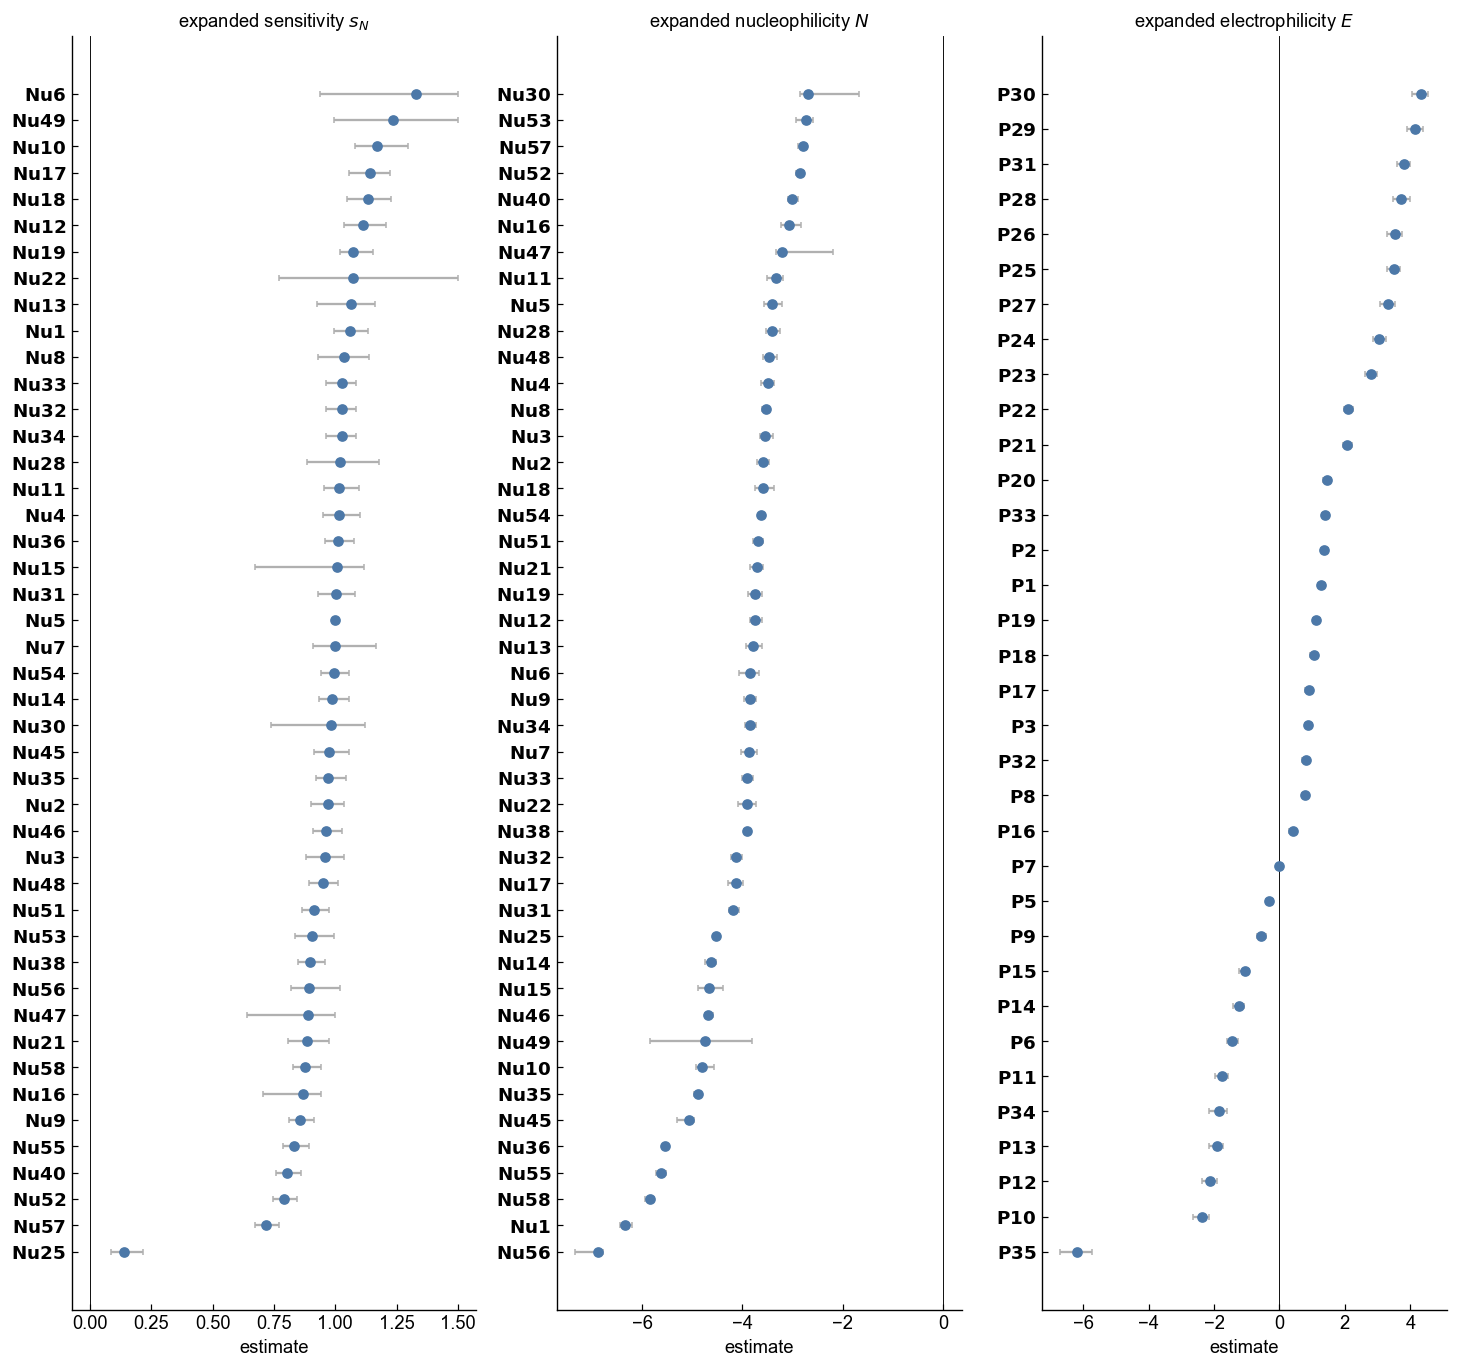

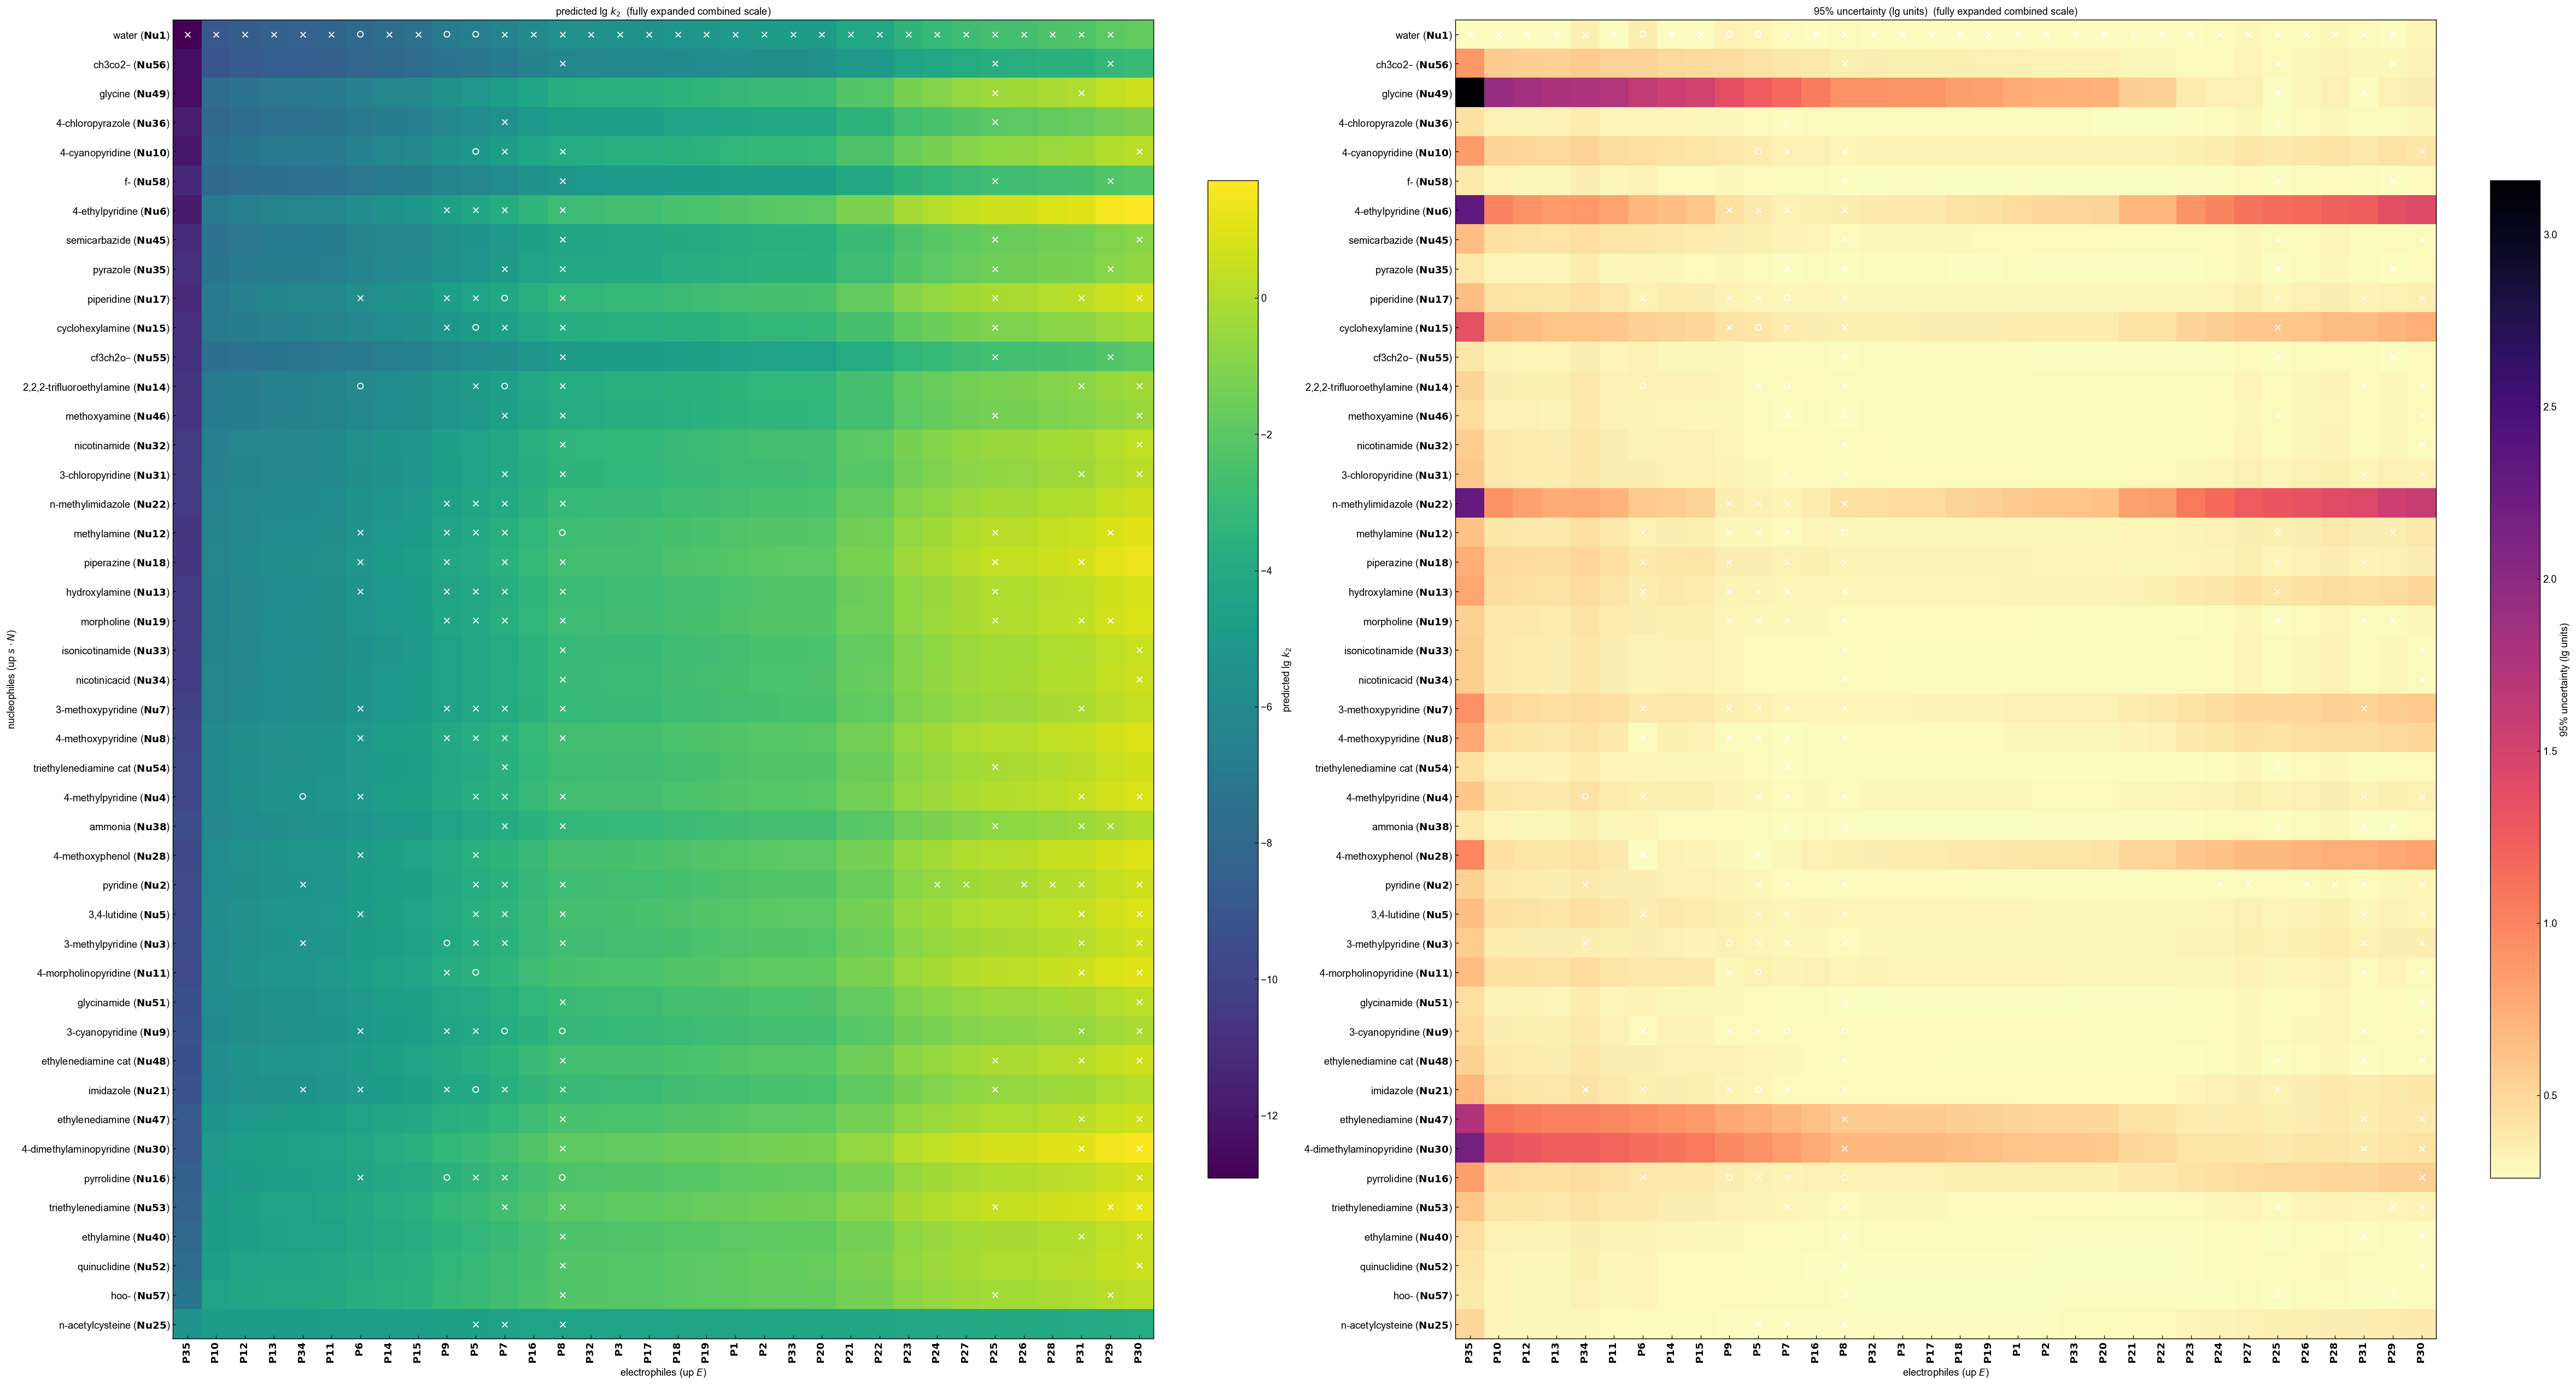

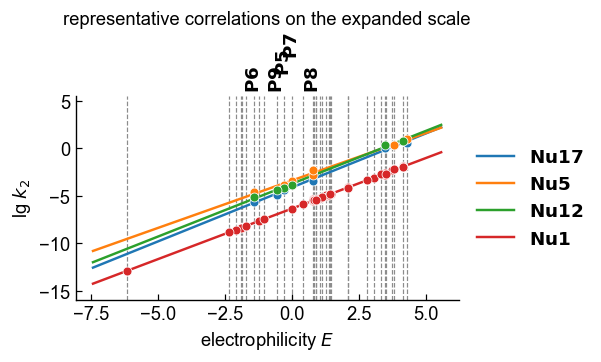

In [17]:
# Assemble the fully expanded scale: the selected joint fit, plus every reportable attachment.
expanded_rows = [
    params.copy(),
    pd.DataFrame([dict(type="electrophile", species=r["electrophile"], parameter="E", estimate=r["E"])
                  for _, r in reportable_E.iterrows()]),
    pd.DataFrame([dict(type="nucleophile", species=r["nucleophile"], parameter=p, estimate=r[p])
                  for _, r in discarded_nuc[discarded_nuc["placed"]].iterrows()
                  for p in ("N", "s")]),
]
expanded_params = (pd.concat(expanded_rows, ignore_index=True, sort=False)
                   .drop_duplicates(["type", "species", "parameter"], keep="first"))

expanded_fit_rows = pd.concat([
    fitted.assign(prediction_origin="selected joint fit"),
    discarded_E_detail.assign(prediction_origin="electrophile attachment"),
    discarded_nuc_fitted.assign(prediction_origin="nucleophile attachment"),
], ignore_index=True, sort=False).dropna(subset=["lgk_calc", "residual"])

expanded_dispersion = float(np.sqrt(np.mean(
    (expanded_fit_rows["residual"] - expanded_fit_rows["residual"].mean())**2)))
print(f"Expanded scale: {expanded_params.query('type==\"nucleophile\"').species.nunique()} nucleophiles, "
      f"{expanded_params.query('type==\"electrophile\"').species.nunique()} electrophiles; "
      f"residual dispersion = {expanded_dispersion:.3f} lg units")

# Parameter intervals across the whole expanded scale.
n_species = attachment_boot_summary.query("parameter in ['N', 's']").species.nunique()
fig, axes = plt.subplots(1, 3, figsize=(13.5, max(5.2, 0.28 * n_species)))
parameter_interval_panel(attachment_boot_summary, "s", axes[0], "expanded sensitivity $s_N$")
parameter_interval_panel(attachment_boot_summary, "N", axes[1], "expanded nucleophilicity $N$")
parameter_interval_panel(attachment_boot_summary, "E", axes[2], "expanded electrophilicity $E$")
plt.tight_layout(); plt.show()

# Reactivity maps. Crosses mark pairs used in the fit or an attachment; open circles mark measured pairs among the represented species that no parameter rests on.
used = set(zip(expanded_fit_rows.nucleophile, expanded_fit_rows.electrophile))
nuc_species = set(expanded_params.query("type=='nucleophile'").species)
elec_species = set(expanded_params.query("type=='electrophile'").species)
studied = combined_raw[combined_raw.nucleophile.isin(nuc_species)
                       & combined_raw.electrophile.isin(elec_species)]
excluded = set(zip(studied.nucleophile, studied.electrophile)) - used
heatmaps(expanded_params, attachment_boot, used, excluded, disp=expanded_dispersion,
         title_suffix="  (fully expanded combined scale)")

plot_lgk_vs_E(expanded_fit_rows, expanded_params, CONFIG.LGK_VS_E_NUCLEOPHILES,
              title="representative correlations on the expanded scale",
              label_all_electrophiles=False)   # 34 agents: name only P5-P9
plt.tight_layout(rect=[0, 0, 1, .84]); plt.show()


## 8. Export results and metadata

Two Excel workbooks are written, to `CONFIG.OUTPUT_FILE` and `CONFIG.METADATA_FILE`:

* the **results** workbook — the electrophile and nucleophile parameter tables with confidence
  intervals, the selected joint-fit reactions, a summary of the fit statistics, and the species that
  could not be placed together with the reason;
* the **metadata** workbook — both raw inputs, the combined table, the selection history, the
  attachment tables, the bootstrap summaries, and the complete parameter table.

In [18]:
def parameter_frame(summary, provenance=""):
    med = summary.pivot_table(index="species", columns=["type", "parameter"], values="median")
    lo = summary.pivot_table(index="species", columns=["type", "parameter"], values="lo95")
    hi = summary.pivot_table(index="species", columns=["type", "parameter"], values="hi95")
    rows = []
    for species in summary.query("type == 'nucleophile'").species.unique():
        rows.append(dict(species=species, role="nucleophile", provenance=provenance,
                         N=med.get(("nucleophile", "N"), {}).get(species),
                         N_lo95=lo.get(("nucleophile", "N"), {}).get(species),
                         N_hi95=hi.get(("nucleophile", "N"), {}).get(species),
                         s=med.get(("nucleophile", "s"), {}).get(species),
                         s_lo95=lo.get(("nucleophile", "s"), {}).get(species),
                         s_hi95=hi.get(("nucleophile", "s"), {}).get(species)))
    for species in summary.query("type == 'electrophile'").species.unique():
        rows.append(dict(species=species, role="electrophile", provenance=provenance,
                         E=med.get(("electrophile", "E"), {}).get(species),
                         E_lo95=lo.get(("electrophile", "E"), {}).get(species),
                         E_hi95=hi.get(("electrophile", "E"), {}).get(species)))
    return pd.DataFrame(rows)


parameter_table = parameter_frame(attachment_boot_summary, "combined_selected_or_discarded_system")
annotations = []
for species in ref_nuc.index:
    annotations.append(dict(species=species, role="nucleophile",
                            placement_method="joint_automated_selection_refit",
                            status="selected from raw combined input", validated=True))
for species in ref_elec.index:
    annotations.append(dict(species=species, role="electrophile",
                            placement_method="joint_automated_selection_refit",
                            status="selected from raw combined input", validated=True))
for _, row in discarded_nuc[discarded_nuc["placed"]].iterrows():
    annotations.append(dict(species=row["nucleophile"], role="nucleophile",
                            placement_method=row["placement_method"], status=row["status"],
                            validated=bool(row["validated"])))
for _, row in reportable_E.iterrows():
    annotations.append(dict(species=row["electrophile"], role="electrophile",
                            placement_method=("fixed_selected_E_from_selected_nucleophiles"
                                              if row["reliable"] else "single_nucleophile_E_definition"),
                            status=row["status"], validated=bool(row["reliable"])))
annotations = pd.DataFrame(annotations).drop_duplicates(["species", "role"], keep="first")
parameter_table = parameter_table.merge(annotations, on=["species", "role"], how="left")

nuc_coverage = (pd.concat([core, discarded_nuc_fitted], ignore_index=True, sort=False)
                .groupby("nucleophile").agg(n_reactions=("lgk", "size"),
                                             n_electrophiles=("electrophile", "nunique"))
                .reset_index().rename(columns={"nucleophile": "species"}))
elec_coverage = (pd.concat([core, discarded_E_detail], ignore_index=True, sort=False)
                 .groupby("electrophile").agg(n_reactions=("lgk", "size"),
                                                n_nucleophiles=("nucleophile", "nunique"))
                 .reset_index().rename(columns={"electrophile": "species"}))
parameter_table = parameter_table.merge(nuc_coverage, on="species", how="left")
parameter_table = parameter_table.merge(elec_coverage, on="species", how="left")

# Export convention: phosphorylating agents are identified by their P number only;
# nucleophiles keep their name together with their Nu number.
def _eid(name):
    return ELECTROPHILE_ID_MAP.get(name, name)

def _nid(name):
    return NUCLEOPHILE_ID_MAP.get(name, name)

def ids_only_electrophiles(df):
    "Replace electrophile name columns by the ID; add a missing nucleophile ID column."
    out = df.copy()
    if "electrophile" in out.columns:
        if "electrophile_id" not in out.columns:
            out.insert(out.columns.get_loc("electrophile"), "electrophile_id",
                       out["electrophile"].map(_eid))
        out = out.drop(columns=["electrophile"])
    if "raw_electrophile_name" in out.columns:
        out = out.drop(columns=["raw_electrophile_name"])
    if "nucleophile" in out.columns and "nucleophile_id" not in out.columns:
        out.insert(out.columns.get_loc("nucleophile") + 1, "nucleophile_id",
                   out["nucleophile"].map(_nid))
    return out

def ids_for_species(df):
    "Parameter-style frames: electrophile species -> ID; species_id column for every row."
    out = df.copy()
    role_col = "role" if "role" in out.columns else "type"
    is_e = (out[role_col] == "electrophile").to_numpy()
    out.insert(out.columns.get_loc("species") + 1, "species_id",
               np.where(is_e, out["species"].map(_eid), out["species"].map(_nid)))
    out.loc[is_e, "species"] = out.loc[is_e, "species"].map(_eid)
    return out


electrophile_parameters = parameter_table.query("role == 'electrophile'").copy()
electrophile_parameters["species"] = electrophile_parameters["species"].map(_eid)
electrophile_parameters = electrophile_parameters.rename(columns={"species": "P_ID"})
nucleophile_parameters = parameter_table.query("role == 'nucleophile'").copy()
nucleophile_parameters.insert(1, "Nu_ID", nucleophile_parameters["species"].map(_nid))

strategy_summary = pd.DataFrame([dict(
    strategy="combined automatic selection + source-neutral discarded-system attachment",
    n_raw=len(combined_raw), n_fit=metrics["n"], n_selected_nucleophiles=metrics["n_nuc"],
    n_selected_electrophiles=metrics["n_elec"], r2=metrics["r2"], rmse=metrics["rmse"],
    n_discarded_nucleophiles_placed=int(discarded_nuc["placed"].sum()),
    n_reliable_discarded_E=len(reliable_E),
    n_single_nucleophile_E_reported=int((reportable_E["export_status"] == "single-nucleophile definition").sum()),
    recommendation="single combined scale; single-nucleophile E values are report-only",
)])

result_readme = pd.DataFrame([
    dict(item="model", value="lg k2 = N_P + s_N,P * E_P"),
    dict(item="primary_scale", value="raw combined HTE + literature automated selection; jointly refitted E/N/s"),
    dict(item="anchor_nucleophile", value="3,4-lutidine: s_N,P = 1; N_P fitted"),
    dict(item="anchor_electrophile", value="P7: E = 0"),
    dict(item="pyridine_attachment", value="selected-pyridine mean s_N,P when required by coverage/consistency rule"),
    dict(item="single_nucleophile_E", value="reported with propagated bootstrap CI; not used for nucleophile placement"),
    dict(item="quality_pre_filter", value="none; all valid combined measurements enter automated selection"),
    dict(item="s_at_bounds", value="freely fitted s at 0 or 1.5 -> species rejected (see rejected_species)"),
    dict(item="metadata_workbook", value=CONFIG.METADATA_FILE),
])

rejected_nuc = discarded_nuc[~discarded_nuc["placed"]].copy()
rejected_nuc = rejected_nuc.assign(role="nucleophile", species=rejected_nuc["nucleophile"],
                                   stage="discarded_system_attachment")
rejected_elec = discarded_E[~discarded_E["placed"]].copy()
rejected_elec = rejected_elec.assign(role="electrophile", species=rejected_elec["electrophile"],
                                     stage="discarded_system_attachment", rejected=False,
                                     reject_reason="")
rejected_species = pd.concat([
    rejected_nuc[["stage", "role", "species", "s", "n_reactions", "n_electrophiles", "rejected", "reject_reason", "status"]],
    rejected_elec[["stage", "role", "species", "n_reactions", "n_nucleophiles", "rejected", "reject_reason", "status"]],
], ignore_index=True, sort=False)
rejected_species = ids_for_species(rejected_species)

def _ids_in_removed(item, reason):
    if reason == "electrophile<min_nuc":
        return _eid(item)
    if reason == "MAD_outlier" and " / " in str(item):
        nuc, rest = str(item).split(" / ", 1)
        elec, _, tail = rest.partition(" (")
        return f"{nuc} / {_eid(elec)}" + (f" ({tail}" if tail else "")
    return item

selection_removed_export = selection_removed.copy()
selection_removed_export["item"] = [_ids_in_removed(i, r) for i, r
                                    in zip(selection_removed_export["item"],
                                           selection_removed_export["reason"])]

metadata_sheets = {
    "input_hte_kinetics": ids_only_electrophiles(own_raw),
    "input_literature": ids_only_electrophiles(lit),
    "combined_raw_input": ids_only_electrophiles(combined_raw),
    "selected_dataset": ids_only_electrophiles(core),
    "core_fit": ids_only_electrophiles(fitted),
    "selection_history": hist_core,
    "selection_removed": selection_removed_export,
    "params_core_bootstrap": ids_for_species(boot_summary),
    "discarded_E_placements": ids_only_electrophiles(reportable_E),
    "discarded_nuc_placements": ids_only_electrophiles(discarded_nuc),
    "discarded_E_fit_rows": ids_only_electrophiles(discarded_E_detail),
    "discarded_nuc_fit_rows": ids_only_electrophiles(discarded_nuc_fitted),
    "attachment_bootstrap": ids_for_species(attachment_boot_summary),
    "expanded_fit_rows": ids_only_electrophiles(expanded_fit_rows),
    "params_all": ids_for_species(parameter_table),
}

with pd.ExcelWriter(CONFIG.OUTPUT_FILE) as xw:
    result_readme.to_excel(xw, sheet_name="README", index=False)
    electrophile_parameters.to_excel(xw, sheet_name="electrophiles", index=False)
    nucleophile_parameters.to_excel(xw, sheet_name="nucleophiles", index=False)
    ids_only_electrophiles(fitted).to_excel(xw, sheet_name="core_fit", index=False)
    strategy_summary.to_excel(xw, sheet_name="strategy_summary", index=False)
    rejected_species.to_excel(xw, sheet_name="rejected_species", index=False)

with pd.ExcelWriter(CONFIG.METADATA_FILE) as xw:
    result_readme.to_excel(xw, sheet_name="README", index=False)
    for sheet, df in metadata_sheets.items():
        df.to_excel(xw, sheet_name=sheet[:31], index=False)

print(f"Wrote results workbook:  {CONFIG.OUTPUT_FILE}  (6 sheets)")
print(f"Wrote metadata workbook: {CONFIG.METADATA_FILE}  ({len(metadata_sheets) + 1} sheets)")
display(parameter_table.sort_values(["role", "species"]).round(3))


Wrote results workbook:  lfer_analysis_v2_results.xlsx  (6 sheets)
Wrote metadata workbook: lfer_analysis_v2_metadata.xlsx  (16 sheets)


,species,role,provenance,N,N_lo95,N_hi95,s,s_lo95,s_hi95,E,E_lo95,E_hi95,placement_method,status,validated,n_reactions_x,n_electrophiles,n_reactions_y,n_nucleophiles
45,"2,4,6-trichlorophenylphosphate",electrophile,combined_selected_or_discarded_system,NaN,NaN,NaN,NaN,NaN,NaN,-1.916,-2.141,-1.731,single_nucleophile_E_definition,reported only; not used for nucleophile placement,False,NaN,NaN,1.0,1.0
46,2-chloro-4-nitrophenylphosphate,electrophile,combined_selected_or_discarded_system,NaN,NaN,NaN,NaN,NaN,NaN,-1.223,-1.410,-1.074,single_nucleophile_E_definition,reported only; not used for nucleophile placement,False,NaN,NaN,1.0,1.0
47,2-nitro-4-COMe-phenylphosphate,electrophile,combined_selected_or_discarded_system,NaN,NaN,NaN,NaN,NaN,NaN,0.409,0.289,0.500,single_nucleophile_E_definition,reported only; not used for nucleophile placement,False,NaN,NaN,1.0,1.0
48,2-nitro-4-chlorophenylphosphate,electrophile,combined_selected_or_discarded_system,NaN,NaN,NaN,NaN,NaN,NaN,-1.063,-1.247,-0.919,single_nucleophile_E_definition,reported only; not used for nucleophile placement,False,NaN,NaN,1.0,1.0
49,2-nitrophenylphosphate,electrophile,combined_selected_or_discarded_system,NaN,NaN,NaN,NaN,NaN,NaN,-1.743,-1.956,-1.568,single_nucleophile_E_definition,reported only; not used for nucleophile placement,False,NaN,NaN,1.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
40,quinuclidine,nucleophile,combined_selected_or_discarded_system,-2.848,-2.934,-2.775,0.790,0.747,0.843,NaN,NaN,NaN,bounded_sN_fit,bounded low-coverage fit,False,2.0,2.0,NaN,NaN
41,semicarbazide,nucleophile,combined_selected_or_discarded_system,-5.065,-5.313,-4.965,0.975,0.913,1.056,NaN,NaN,NaN,joint_automated_selection_refit,selected from raw combined input,True,3.0,3.0,NaN,NaN
42,triethylenediamine,nucleophile,combined_selected_or_discarded_system,-2.724,-2.925,-2.598,0.906,0.837,0.994,NaN,NaN,NaN,joint_automated_selection_refit,selected from raw combined input,True,6.0,5.0,NaN,NaN
43,triethylenediamine cat,nucleophile,combined_selected_or_discarded_system,-3.638,-3.638,-3.638,0.994,0.940,1.058,NaN,NaN,NaN,bounded_sN_fit,bounded low-coverage fit,False,2.0,2.0,NaN,NaN
